# Code Implementation for Comparative Analysis of XAI Methods for Lung Nodule Detection using LUNA16



## Instructions to run XAI implementation, in this order:
1. Installs and imports
2. Dataloaders
3. Loading the models trained on LUNA16
4. Finding the best threshold
5. Setup for XAI
6. All XAI class definitions and helper functions

At this point it is possible to run the XAI on a set of images, as seen in the code cells below the XAI class definitions. The evaluation metrics are defined below these cells, and can be tested by sequentially running all metric helper functions and definitions.

All XAI evaluation results have been printed in the final cells.

# Installs and Imports

In [ ]:
# Install SimpleITK (necessary to read .mhd/.raw files)
!pip install SimpleITK -q

# Install LIME for XAI implementation
!pip install lime
# Install SHAP for XAI implementation
!pip install shap -q

# All imports
import os
import glob
import shutil
import pickle
import numpy as np
import pandas as pd
import SimpleITK as sitk
from skimage.segmentation import clear_border
import matplotlib.pyplot as plt
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import torchvision.transforms.functional as TF
from google.colab import drive
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import models
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import transforms
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from lime import lime_image
import shap
import matplotlib.patches as patches
from skimage.segmentation import mark_boundaries
from sklearn.metrics import jaccard_score
from skimage.metrics import structural_similarity as ssim

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f'Using {device}')

# Mount Google Drive for permanent, safe storage
drive.mount('/content/drive')

# Setup paths on Google Drive
output_dir = "/content/drive/MyDrive/LUNA16_Processed"
os.makedirs(output_dir, exist_ok=True)

x_train_path = os.path.join(output_dir, "X_train.npy")
y_train_path = os.path.join(output_dir, "y_train.npy")
m_train_path = os.path.join(output_dir, "m_train.npy")
x_val_path = os.path.join(output_dir, "X_val.npy")
y_val_path = os.path.join(output_dir, "y_val.npy")
m_val_path = os.path.join(output_dir, "m_val.npy")
x_test_path = os.path.join(output_dir, "X_test.npy")
y_test_path = os.path.join(output_dir, "y_test.npy")
m_test_path = os.path.join(output_dir, "m_test.npy")

model_dir = "/content/drive/MyDrive/Models"
os.makedirs(model_dir, exist_ok=True)

resnet50_path = os.path.join(model_dir, "resnet50.pth")
vgg16_path = os.path.join(model_dir, "vgg16.pth")

results_dir = os.path.join(model_dir, "Results")
os.makedirs(results_dir, exist_ok=True)

# Change the evaluation directory to whichever folder you are saving the results in
evaluation_dir = "/content/drive/MyDrive/LatestHonsProject/PointingGameEvaluation"
os.makedirs(evaluation_dir, exist_ok=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 14.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=2d637068e9db64f036ed1796530a2d01b893da5a213938b21d25f97fdc159abf
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
Using cuda
Mounted at /content/drive


# Preprocessing

Code sources:

*   https://simpleitk.readthedocs.io/en/master/fundamentalConcepts.html
*   https://github.com/mikejhuang/LungNoduleDetectionClassification/blob/master/1ProcessNoduleDataset.ipynb
*   https://github.com/s-mostafa-a/Luna16/blob/master/notebooks/Preprocessor.ipynb
*   https://github.com/qiuliwang/LIDC-IDRI-Toolbox-python
*   https://www.kaggle.com/code/gzuidhof/full-preprocessing-tutorial
*   https://www.kaggle.com/code/arnavkj95/candidate-generation-and-luna16-preprocessing


Why we used a Hounsfield Unit range of [-950,-500] to identify lung tissue:
* https://www.nature.com/articles/s41598-019-41510-9




In [ ]:
# Reproducibility
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)

set_seed(42)

In [ ]:
# Preprocessing Helper Functions
def normalize_hu(slice_img):
    """
    Applies Intensity Normalisation.
    Clips Hounsfield Units to the lung window [-1000, 400] and scales to [0, 1].
    """
    slice_img = np.clip(slice_img, -1000, 400)
    slice_img = (slice_img + 1000) / 1400.0
    return slice_img.astype(np.float32)

def is_valid_lung_slice(raw_slice_hu, min_lung_ratio=0.05):
    """
    Checks if a 2D slice contains a suffient proportion of lung tissue.
    """
    # Intensity check
    lung_pixels = np.sum((raw_slice_hu >= -950) & (raw_slice_hu <= -500))

    total_pixels = raw_slice_hu.size

    return (lung_pixels / total_pixels) >= min_lung_ratio

def extract_balanced_slices_from_scan(mhd_path, df_anno, target_size=(224, 224)):
    """
    Processes a single scan. Extracts all known nodule slices (Class 1),
    then extracts an equal number of non-nodule slices (Class 0) from the same scan.
    If the scan is a true negative, it safely extracts 1 clean baseline slice.
    Create bounding box masks for all slices.
    Class 1: Nodule slice with a localised bounding box mask.
    Class 0: Clean negative slice with an empty mask (all zeros).
    """
    slices_list = []
    labels_list = []
    masks_list = []

    uid = os.path.basename(mhd_path).replace('.mhd', '')

    # Read the 3D volume image
    itk_image = sitk.ReadImage(mhd_path)
    vol = sitk.GetArrayFromImage(itk_image) # Shape: (Z, Y, X)

    # Extract physical voxel spacing to convert mm to pixels accurately
    spacing_x, spacing_y, spacing_z = itk_image.GetSpacing()

    # Find annotations for this specific scan
    patient_nodules = df_anno[df_anno['seriesuid'] == uid]
    nodule_z_slices = set()
    all_nodule_z_slices = set()

    # Extract Positive Slices (Class 1)
    if len(patient_nodules) > 0:
        for _, row in patient_nodules.iterrows():
            world_point = (row['coordX'], row['coordY'], row['coordZ'])
            itk_voxel_coord = itk_image.TransformPhysicalPointToIndex(world_point)
            v_x, v_y, z_idx = itk_voxel_coord

            diameter_mm = row.get('diameter_mm', 10.0)
            radius_z = int(np.ceil((diameter_mm / 2) / spacing_z))

            # Calculate the full range of slices a nodule occupies
            z_start = max(0, z_idx - radius_z)
            z_end = min(vol.shape[0], z_idx + radius_z + 1)

            # Blacklist all slices containing any part of the nodule
            for z in range(z_start, z_end):
                all_nodule_z_slices.add(z)

            if 0 <= z_idx < vol.shape[0]:
                raw_slice = vol[z_idx, :, :]
                norm_slice = normalize_hu(raw_slice)
                resized_slice = cv2.resize(norm_slice, target_size, interpolation=cv2.INTER_AREA)

                # Create the binary mask for the nodule
                raw_mask = np.zeros_like(raw_slice, dtype=np.uint8)

                # Convert mm radius to pixel radius
                radius_x = int(max(1, (diameter_mm / 2) / spacing_x))
                radius_y = int(max(1, (diameter_mm / 2) / spacing_y))

                # Define bounding box boundaries
                y_min = max(0, v_y - radius_y)
                y_max = min(raw_mask.shape[0], v_y + radius_y)
                x_min = max(0, v_x - radius_x)
                x_max = min(raw_mask.shape[1], v_x + radius_x)

                # Draw the bounding box
                raw_mask[y_min:y_max, x_min:x_max] = 1

                # Resize mask. Use INTER_NEAREST to preserve discrete 0 and 1 boundaries
                resized_mask = cv2.resize(raw_mask, target_size, interpolation=cv2.INTER_NEAREST)

                slices_list.append(resized_slice)
                labels_list.append(1)
                masks_list.append(resized_mask)
                nodule_z_slices.add(z_idx)

    # Extract Negative Slices (Class 0) and create empty masks
    # Pull an equal number of negative slices to keep it perfectly balanced per patient.
    # If the patient has 0 nodules, pull 1 clean control slice.
    num_neg_to_pull = max(1, len(nodule_z_slices))

    possible_neg_indices = []
    start_idx = int(vol.shape[0] * 0.2)
    end_idx = int(vol.shape[0] * 0.8)

    for z in range(start_idx, end_idx):
        if z in all_nodule_z_slices:
            continue
        if is_valid_lung_slice(vol[z]):
            possible_neg_indices.append(z)

    if len(possible_neg_indices) > 0:
        # Sample from the index space, avoiding gaps
        indices = np.linspace(0, len(possible_neg_indices) - 1, num_neg_to_pull, dtype=int)
        selected_z_indices = [possible_neg_indices[i] for i in indices]

        for z_idx in selected_z_indices:
            raw_slice = vol[z_idx, :, :]
            norm_slice = normalize_hu(raw_slice)
            resized_slice = cv2.resize(norm_slice, target_size, interpolation=cv2.INTER_AREA)

            # Create a completely blank mask for healthy slices
            empty_mask = np.zeros(target_size, dtype=np.uint8)

            slices_list.append(resized_slice)
            labels_list.append(0)
            masks_list.append(empty_mask)

    return np.array(slices_list, dtype=np.float32), np.array(labels_list, dtype=np.int64), np.array(masks_list, dtype=np.uint8)

# Incremental appending helper function
def append_to_npy(file_path, new_data):
    """Appends new array data to an existing .npy file on disk without loading the whole file into RAM."""
    if not os.path.exists(file_path):
        np.save(file_path, new_data)
    else:
        existing_data = np.load(file_path)
        combined_data = np.vstack((existing_data, new_data)) if len(new_data.shape) > 1 else np.concatenate((existing_data, new_data))
        np.save(file_path, combined_data)

In [ ]:
# Download the annotations file once
!wget -O ./annotations.csv https://zenodo.org/records/3723295/files/annotations.csv?download=1
df_annotations = pd.read_csv('./annotations.csv')

# Dict mapping subset indices of LUNA16 to Zenodo links
subset_urls = {
    0: "https://zenodo.org/records/3723295/files/subset0.zip?download=1",
    1: "https://zenodo.org/records/3723295/files/subset1.zip?download=1",
    2: "https://zenodo.org/records/3723295/files/subset2.zip?download=1",
    3: "https://zenodo.org/records/3723295/files/subset3.zip?download=1",
    4: "https://zenodo.org/records/3723295/files/subset4.zip?download=1",
    5: "https://zenodo.org/records/3723295/files/subset5.zip?download=1",
    6: "https://zenodo.org/records/3723295/files/subset6.zip?download=1",
    7: "https://zenodo.org/records/4121926/files/subset7.zip?download=1",
    8: "https://zenodo.org/records/4121926/files/subset8.zip?download=1",
    9: "https://zenodo.org/records/4121926/files/subset9.zip?download=1",
}

for i in range(10): # Loop from subset 0 to 9
    print(f"\n================ STARTING SUBSET {i} ================")

    if i not in subset_urls:
        print(f"URL missing for subset {i}, skipping.")
        continue

    local_zip = f"subset{i}.zip"
    local_extract_dir = f"./subset{i}_data"

    # Download
    print(f"Downloading Subset {i}...")
    os.system(f"wget -O {local_zip} {subset_urls[i]}")

    # Extract Zip
    print(f"Unzipping Subset {i}...")
    os.system(f"unzip -q -o {local_zip} -d {local_extract_dir}")

    # Locate files inside the newly extracted directory
    actual_data_path = local_extract_dir
    for root, dirs, files in os.walk(local_extract_dir):
        if any(f.endswith('.mhd') for f in files):
            actual_data_path = root
            break

    all_mhd_files = glob.glob(os.path.join(actual_data_path, "*.mhd"))

    if len(all_mhd_files) == 0:
        print(f"No .mhd files found in Subset {i}, skipping.")
        continue

    # Split the files for this subset (70% Train, 10% Val, 20% Test)
    # Using a subset-dependent seed (42 + i) maintains distribution variance while staying deterministic
    train_val_files, test_files = train_test_split(all_mhd_files, test_size=0.20, random_state=42 + i)
    train_files, val_files = train_test_split(train_val_files, test_size=0.125, random_state=42 + i)

    # Temporary lists to pool data slices and masks within this specific subset pass
    X_tr_sub, y_tr_sub, m_tr_sub = [], [], []
    X_va_sub, y_va_sub, m_va_sub = [], [], []
    X_te_sub, y_te_sub, m_te_sub = [], [], []

    # Extract balanced slices per scan partition
    print(f"Processing Train slices for Subset {i}...")
    for fpath in train_files:
        X_s, y_s, m_s = extract_balanced_slices_from_scan(fpath, df_annotations)
        if len(X_s) > 0:
            X_tr_sub.extend(X_s)
            y_tr_sub.extend(y_s)
            m_tr_sub.extend(m_s)

    print(f"Processing Validation slices for Subset {i}...")
    for fpath in val_files:
        X_s, y_s, m_s = extract_balanced_slices_from_scan(fpath, df_annotations)
        if len(X_s) > 0:
            X_va_sub.extend(X_s)
            y_va_sub.extend(y_s)
            m_va_sub.extend(m_s)

    print(f"Processing Test slices for Subset {i}...")
    for fpath in test_files:
        X_s, y_s, m_s = extract_balanced_slices_from_scan(fpath, df_annotations)
        if len(X_s) > 0:
            X_te_sub.extend(X_s)
            y_te_sub.extend(y_s)
            m_te_sub.extend(m_s)

    # Append subset pools to master arrays on Drive with random shuffling per block
    if len(X_tr_sub) > 0:
        X_tr_sub, y_tr_sub = np.array(X_tr_sub, dtype=np.float32), np.array(y_tr_sub, dtype=np.int64)
        m_tr_sub = np.array(m_tr_sub, dtype=np.uint8)
        idx = np.random.permutation(len(X_tr_sub))
        append_to_npy(os.path.join(output_dir, "X_train.npy"), X_tr_sub[idx])
        append_to_npy(os.path.join(output_dir, "y_train.npy"), y_tr_sub[idx])
        append_to_npy(os.path.join(output_dir, "m_train.npy"), m_tr_sub[idx])

    if len(X_va_sub) > 0:
        X_va_sub, y_va_sub = np.array(X_va_sub, dtype=np.float32), np.array(y_va_sub, dtype=np.int64)
        m_va_sub = np.array(m_va_sub, dtype=np.uint8)
        idx = np.random.permutation(len(X_va_sub))
        append_to_npy(os.path.join(output_dir, "X_val.npy"), X_va_sub[idx])
        append_to_npy(os.path.join(output_dir, "y_val.npy"), y_va_sub[idx])
        append_to_npy(os.path.join(output_dir, "m_val.npy"), m_va_sub[idx])

    if len(X_te_sub) > 0:
        X_te_sub, y_te_sub = np.array(X_te_sub, dtype=np.float32), np.array(y_te_sub, dtype=np.int64)
        m_te_sub = np.array(m_te_sub, dtype=np.uint8)
        idx = np.random.permutation(len(X_te_sub))
        append_to_npy(os.path.join(output_dir, "X_test.npy"), X_te_sub[idx])
        append_to_npy(os.path.join(output_dir, "y_test.npy"), y_te_sub[idx])
        append_to_npy(os.path.join(output_dir, "m_test.npy"), m_te_sub[idx])

    # Cleanup storage
    print(f"Cleaning up files for Subset {i} ...")
    if os.path.exists(local_zip):
        os.remove(local_zip)
    if os.path.exists(local_extract_dir):
        shutil.rmtree(local_extract_dir)

    print(f"================ FINISHED SUBSET {i} ================")

print("\nSuccess! The entire LUNA16 dataset is processed and stored on Google Drive!")

--2026-08-05 17:41:16--  https://zenodo.org/records/3723295/files/annotations.csv?download=1
Resolving zenodo.org (zenodo.org)... 188.184.103.118, 188.185.43.153, 137.138.153.219, ...
Connecting to zenodo.org (zenodo.org)|188.184.103.118|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 136986 (134K) [text/plain]
Saving to: ‘./annotations.csv’

./annotations.csv   100%[===================>] 133.78K   320KB/s    in 0.4s    

2026-08-05 17:41:17 (320 KB/s) - ‘./annotations.csv’ saved [136986/136986]


================ STARTING SUBSET 0 ================
Unzipping Subset 0...
Processing Train slices for Subset 0...
Processing Validation slices for Subset 0...
Processing Test slices for Subset 0...
Cleaning up files for Subset 0 ...
================ FINISHED SUBSET 0 ================

================ STARTING SUBSET 1 ================
Unzipping Subset 1...
Processing Train slices for Subset 1...
Processing Validation slices for Subset 1...
Processing Test slices for

# Data Inspection

Total processed training slices found on Drive: 1811


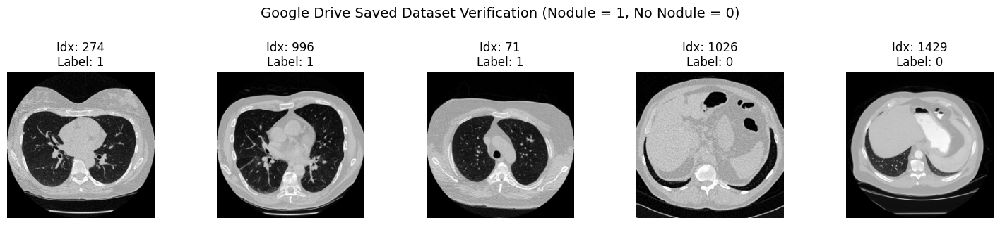

In [ ]:
# Visualise
# Define the Google Drive directory where the pipeline saved files
output_dir = "/content/drive/MyDrive/LUNA16_Processed"

x_train_path = os.path.join(output_dir, "X_train.npy")
y_train_path = os.path.join(output_dir, "y_train.npy")

if os.path.exists(x_train_path) and os.path.exists(y_train_path):
    # Use mmap_mode='r' to safely view files without loading the massive multi-gigabyte array into RAM
    X_train_view = np.load(x_train_path, mmap_mode='r')
    y_train_view = np.load(y_train_path, mmap_mode='r')

    total_samples = X_train_view.shape[0]
    print(f"Total processed training slices found on Drive: {total_samples}")

    # Choose a few random indices to display
    num_samples = 5
    # np.random.seed(12) # Change seed to look at different random slices
    random_indices = np.random.choice(total_samples, num_samples, replace=False)

    # Plotting pipeline
    fig, axes = plt.subplots(1, num_samples, figsize=(num_samples * 3, 3))
    fig.suptitle("Google Drive Saved Dataset Verification (Nodule = 1, No Nodule = 0)", fontsize=14, y=1.05)

    for idx, img_idx in enumerate(random_indices):
        ax = axes[idx]

        # Pull only the single specific slice into RAM memory
        img = X_train_view[img_idx]
        label = y_train_view[img_idx]

        # Display slice (already normalized to [0, 1] bounds from your pipeline)
        ax.imshow(img, cmap='gray')
        ax.set_title(f"Idx: {img_idx}\nLabel: {label}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Files not found yet.")



1.   Displays the % split and sample counts across the Train, Validation and Test sets
2.   Displays grid of Positive (Nodule) and Negative (No Nodule)



================ DATASET DISTRIBUTION SUMMARY ================

--- Train Set ---
Total Slices: 1811
   Nodules (Class 1):    807    (44.56%)
   No Nodules (Class 0): 1004   (55.44%)

--- Validation Set ---
Total Slices: 308
   Nodules (Class 1):    141    (45.78%)
   No Nodules (Class 0): 167    (54.22%)

--- Test Set ---
Total Slices: 530
   Nodules (Class 1):    238    (44.91%)
   No Nodules (Class 0): 292    (55.09%)

================ VISUALIZING POSITIVE VS NEGATIVE SLICES ================



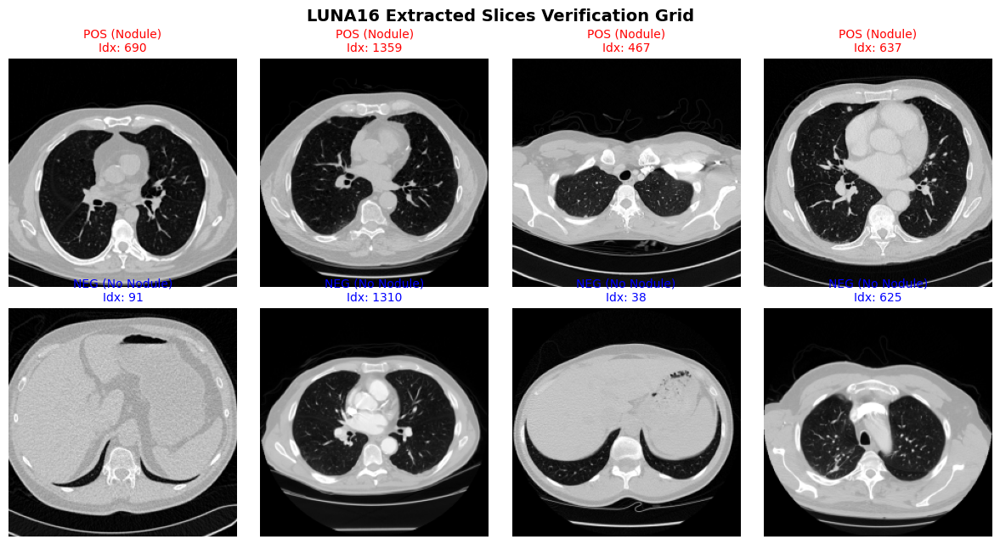

In [ ]:
output_dir = "/content/drive/MyDrive/LUNA16_Processed"


# Define the sets to analyse
datasets = {
    'Train': ('X_train.npy', 'y_train.npy'),
    'Validation': ('X_val.npy', 'y_val.npy'),
    'Test': ('X_test.npy', 'y_test.npy')
}

print("================ DATASET DISTRIBUTION SUMMARY ================\n")

# Store memory-mapped references for visualisation later
mmap_data = {}

for set_name, (x_file, y_file) in datasets.items():
    x_path = os.path.join(output_dir, x_file)
    y_path = os.path.join(output_dir, y_file)

    if os.path.exists(x_path) and os.path.exists(y_path):
        # Memory map arrays
        X_view = np.load(x_path, mmap_mode='r')
        y_view = np.load(y_path, mmap_mode='r')

        mmap_data[set_name] = (X_view, y_view)

        total_samples = len(y_view)
        # Count classes (0 = No Nodule, 1 = Nodule)
        num_neg = np.sum(y_view == 0)
        num_pos = np.sum(y_view == 1)

        pct_neg = (num_neg / total_samples) * 100 if total_samples > 0 else 0
        pct_pos = (num_pos / total_samples) * 100 if total_samples > 0 else 0

        print(f"--- {set_name} Set ---")
        print(f"Total Slices: {total_samples}")
        print(f"   Nodules (Class 1):    {num_pos:<6} ({pct_pos:.2f}%)")
        print(f"   No Nodules (Class 0): {num_neg:<6} ({pct_neg:.2f}%)\n")
    else:
        print(f" Warning: Files for {set_name} set were not found at {output_dir}.\n")

print("================ VISUALIZING POSITIVE VS NEGATIVE SLICES ================\n")

# Visual Inspection (Using Train Set)
if 'Train' in mmap_data:
    X_train, y_train = mmap_data['Train']

    # Find indices for both classes
    pos_indices = np.where(y_train == 1)[0]
    neg_indices = np.where(y_train == 0)[0]

    num_visualize = 4  # Number of samples to show per class
    #np.random.seed(42)  # For reproducible inspection

    selected_pos = np.random.choice(pos_indices, min(num_visualize, len(pos_indices)), replace=False)
    selected_neg = np.random.choice(neg_indices, min(num_visualize, len(neg_indices)), replace=False)

    # Plotting grid
    fig, axes = plt.subplots(2, num_visualize, figsize=(num_visualize * 3, 6.5))

    # Plot Positive Nodule Samples (Row 1)
    for idx, img_idx in enumerate(selected_pos):
        ax = axes[0, idx]
        ax.imshow(X_train[img_idx], cmap='gray')
        ax.set_title(f"POS (Nodule)\nIdx: {img_idx}", color='red', fontsize=10)
        ax.axis('off')

    # Plot Negative No-Nodule Samples (Row 2)
    for idx, img_idx in enumerate(selected_neg):
        ax = axes[1, idx]
        ax.imshow(X_train[img_idx], cmap='gray')
        ax.set_title(f"NEG (No Nodule)\nIdx: {img_idx}", color='blue', fontsize=10)
        ax.axis('off')

    plt.suptitle("LUNA16 Extracted Slices Verification Grid", fontsize=14, weight='bold', y=0.98)
    plt.tight_layout()
    plt.show()
else:
    print("Could not visualize: Training array views are missing.")

# Training of ResNet50 and VGG16 via Transfer Learning
Code Sources:
* https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
* https://docs.pytorch.org/vision/0.29/models/generated/torchvision.models.resnet50.html
* https://docs.pytorch.org/vision/main/models/generated/torchvision.models.vgg16.html

In [ ]:
# Load ImageNet pretrained models
# ResNet-50
resnet50 = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# Replace the final fully connected layer
num_ftrs = resnet50.fc.in_features
resnet50.fc = nn.Linear(num_ftrs, 1)


# VGG-16
vgg16 = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
# Replace the final layer in the classifier block
num_ftrs = vgg16.classifier[6].in_features
vgg16.classifier[6] = nn.Linear(num_ftrs, 1)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 136MB/s]


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 69.7MB/s]


In [ ]:
#Prepare data loaders
class DatasetLoader(Dataset):
    def __init__(self, x_data, y_data, transform=None):
        """
        x_data: NumPy array of images (Shape: [N, 224, 224])
        y_data: NumPy array of labels (Shape: [N])
        transform: Optional torchvision transforms for data augmentation
        """
        self.x_data = x_data
        self.y_data = y_data
        self.transform = transform

        # Data centered around the ImageNet mean/std.
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        # Grab the 224x224 float32 slice
        img_2d = self.x_data[idx]

        # Convert to a PyTorch tensor and create 3 channels -> shape: (3, 224, 224)
        img_tensor = torch.tensor(img_2d, dtype=torch.float32)
        img_3d = img_tensor.unsqueeze(0).repeat(3, 1, 1)

        # Apply Data Augmentation first
        # Torchvision transforms expect the tensor to be in (C, H, W) format
        if self.transform:
            img_3d = self.transform(img_3d)

        # Apply ImageNet normalisation after augmentation
        img_ready = self.normalize(img_3d)

        # Grab the label
        label = torch.tensor(self.y_data[idx], dtype=torch.float32)

        return img_ready, label

# Define training augmentations
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=15,             # Max 15-degree rotation
        translate=(0.05, 0.05), # Max 5% shift
        scale=(0.95, 1.05),     # Zoom between 95% and 105%
    )
])

# Create DataLoaders
print("Loading .npy arrays...")
x_train = np.load(x_train_path)
y_train = np.load(y_train_path)

x_val = np.load(x_val_path)
y_val = np.load(y_val_path)

x_test = np.load(x_test_path)
y_test = np.load(y_test_path)

# Pass the transform only to the training dataset
train_loader = DataLoader(DatasetLoader(x_train, y_train, transform=train_transform), batch_size=32, shuffle=True)
val_loader   = DataLoader(DatasetLoader(x_val, y_val, transform=None), batch_size=32, shuffle=False)
test_loader  = DataLoader(DatasetLoader(x_test, y_test, transform=None), batch_size=32, shuffle=False, pin_memory=True)

Loading .npy arrays...


In [ ]:
#Train models
def train_and_validate(model, learning_rate,  train_loader, val_loader, num_epochs, device, save_path):
    model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    best_val_loss = float('inf')

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        # Training
        model.train()
        train_loss = 0.0
        train_correct = 0
        total_train = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device).float().unsqueeze(1)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            preds = (torch.sigmoid(outputs) >= 0.5).float()
            train_correct += (preds == labels).sum().item()
            total_train += labels.size(0)

        train_loss = train_loss / total_train
        train_acc = train_correct / total_train

        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        total_val = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device).float().unsqueeze(1)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                preds = (torch.sigmoid(outputs) >= 0.5).float()
                val_correct += (preds == labels).sum().item()
                total_val += labels.size(0)

        val_loss = val_loss / total_val
        val_acc = val_correct / total_val

        # Store history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f'Epoch {epoch+1}/{num_epochs} | '
              f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            print(f"--> Saved better model to {save_path}")

    return history

#Train ResNet50
print("Training ResNet50:")
resnet_history = train_and_validate(resnet50, 1e-4,  train_loader, val_loader, 30, device, resnet50_path)

print()
#Train VGG16
print("Training VGG16:")
vgg_history = train_and_validate(vgg16, 1e-4, train_loader, val_loader, 30, device, vgg16_path)


Training ResNet50:
Epoch 1/30 | Train Loss: 0.5462 Acc: 0.7140 | Val Loss: 0.5396 Acc: 0.7013
--> Saved better model to /content/drive/MyDrive/Models/resnet50.pth
Epoch 2/30 | Train Loss: 0.4752 Acc: 0.7824 | Val Loss: 0.5351 Acc: 0.7273
--> Saved better model to /content/drive/MyDrive/Models/resnet50.pth
Epoch 3/30 | Train Loss: 0.4569 Acc: 0.7885 | Val Loss: 0.5445 Acc: 0.7403
Epoch 4/30 | Train Loss: 0.4248 Acc: 0.8012 | Val Loss: 0.5540 Acc: 0.7435
Epoch 5/30 | Train Loss: 0.3860 Acc: 0.8100 | Val Loss: 0.5530 Acc: 0.7468
Epoch 6/30 | Train Loss: 0.3689 Acc: 0.8222 | Val Loss: 0.4759 Acc: 0.7532
--> Saved better model to /content/drive/MyDrive/Models/resnet50.pth
Epoch 7/30 | Train Loss: 0.3239 Acc: 0.8504 | Val Loss: 0.6472 Acc: 0.7500
Epoch 8/30 | Train Loss: 0.2998 Acc: 0.8664 | Val Loss: 0.5567 Acc: 0.7597
Epoch 9/30 | Train Loss: 0.2905 Acc: 0.8669 | Val Loss: 0.6356 Acc: 0.7532
Epoch 10/30 | Train Loss: 0.2521 Acc: 0.8868 | Val Loss: 0.9513 Acc: 0.7662
Epoch 11/30 | Train Los

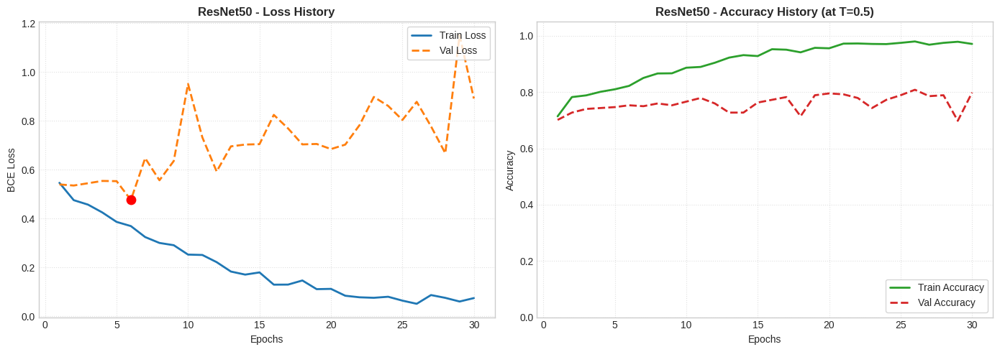

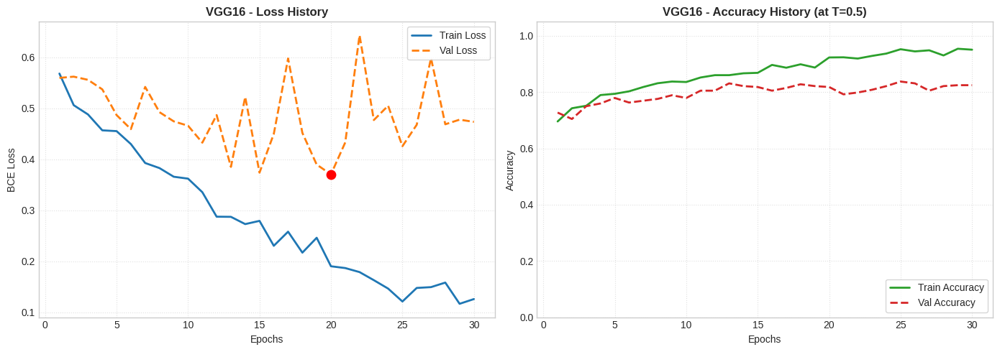

In [ ]:
#Training visualisation
def plot_training_curves(history, model_name="Model"):
    """
    Plots side-by-side loss and accuracy curves for training and validation across epochs.

    Parameters:
        history (dict): Dictionary with keys 'train_loss', 'val_loss', 'train_acc', 'val_acc'
        model_name (str): Title prefix for the plot
    """
    epochs = range(1, len(history['train_loss']) + 1)

    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Subplot 1: Loss Curves
    ax1.plot(epochs, history['train_loss'], label='Train Loss', color='#1f77b4', linewidth=2)
    ax1.plot(epochs, history['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2, linestyle='--')
    ax1.set_title(f'{model_name} - Loss History', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Epochs', fontsize=10)
    ax1.set_ylabel('BCE Loss', fontsize=10)
    ax1.legend(loc='upper right', frameon=True)
    ax1.grid(True, linestyle=':', alpha=0.6)

    # Highlight epoch with lowest validation loss
    min_val_loss_idx = np.argmin(history['val_loss'])
    ax1.scatter(min_val_loss_idx + 1, history['val_loss'][min_val_loss_idx],
                color='red', s=80, zorder=5, label='Best Checkpoint')

    # Subplot 2: Accuracy Curves
    ax2.plot(epochs, history['train_acc'], label='Train Accuracy', color='#2ca02c', linewidth=2)
    ax2.plot(epochs, history['val_acc'], label='Val Accuracy', color='#d62728', linewidth=2, linestyle='--')
    ax2.set_title(f'{model_name} - Accuracy History (at T=0.5)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Epochs', fontsize=10)
    ax2.set_ylabel('Accuracy', fontsize=10)
    ax2.set_ylim(0, 1.05)
    ax2.legend(loc='lower right', frameon=True)
    ax2.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

plot_training_curves(resnet_history, "ResNet50")
plot_training_curves(vgg_history, "VGG16")

In [ ]:
# Load models trained on LUNA16
# ResNet50
resnet50 = models.resnet50(weights=None)
num_ftrs = resnet50.fc.in_features
resnet50.fc = nn.Linear(num_ftrs, 1)

resnet50.load_state_dict(torch.load(resnet50_path,map_location=device))
resnet50.to(device)

# VGG16
vgg16 = models.vgg16(weights=None)
num_ftrs = vgg16.classifier[6].in_features
vgg16.classifier[6] = nn.Linear(num_ftrs, 1)
vgg16.load_state_dict(torch.load(vgg16_path,map_location=device))
vgg16.to(device)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

### Model Evaluation on Test Set

In [ ]:
#Find best threshold
def find_best_threshold(val_labels, val_probs, name):
    """
    Calculates the optimal decision threshold using Youden's J statistic on validation predictions.

    Parameters:
        val_labels : Ground truth binary labels (0 or 1)
        val_probs : Predicted probabilities from sigmoid output (0.0 to 1.0)

    Returns:
        float: The optimal classification threshold
    """
    # Compute ROC curve
    fpr, tpr, thresholds = roc_curve(val_labels, val_probs)

    # Calculate Youden's J Statistic: J = TPR - FPR (Sensitivity + Specificity - 1)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)

    # Clip to bounds [0.0, 1.0] to handle sklearn threshold[0] boundary edge cases
    best_threshold = float(np.clip(thresholds[best_idx], 0.0, 1.0))
    best_j = j_scores[best_idx]

    # Print diagnostic overview
    print("=" * 45)
    print(f"      {name} OPTIMAL THRESHOLD CALCULATION       ")
    print("=" * 45)
    print(f"Optimal Threshold  : {best_threshold:.4f}")
    print(f"Sensitivity (TPR)  : {tpr[best_idx]:.2%}")
    print(f"Specificity (1-FPR): {1 - fpr[best_idx]:.2%}")
    print(f"J : {best_j:.4f}")
    print("=" * 45)

    return best_threshold

def validate_model(model, data_loader, device):
    """
    Return model predictions on validation set.
    """
    model.eval()
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            probs = torch.sigmoid(outputs).squeeze()

            all_labels.extend(labels.cpu().numpy().flatten())
            all_probs.extend(probs.cpu().numpy().flatten())

    return all_labels, all_probs


# Get validation predictions for each model
resnet_labels, resnet_probs = validate_model(resnet50, val_loader, device)
vgg_labels, vgg_probs = validate_model(vgg16, val_loader, device)

# Set a threshold for saving metrics
resnet50_threshold = find_best_threshold(resnet_labels, resnet_probs, "RESNET50")
vgg16_threshold = find_best_threshold(vgg_labels, vgg_probs, "VGG16")

      RESNET50 OPTIMAL THRESHOLD CALCULATION       
Optimal Threshold  : 0.5683
Sensitivity (TPR)  : 78.01%
Specificity (1-FPR): 77.25%
J : 0.5526
      VGG16 OPTIMAL THRESHOLD CALCULATION       
Optimal Threshold  : 0.5324
Sensitivity (TPR)  : 86.52%
Specificity (1-FPR): 80.24%
J : 0.6676


In [ ]:
def evaluate_model(model, data_loader, threshold, device):
    model.eval()
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            probs = torch.sigmoid(outputs).squeeze()
            preds = (probs >= threshold).float()

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    roc_auc = roc_auc_score(all_labels, all_probs)
    tn, fp, fn, tp = confusion_matrix(all_labels, all_preds).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    cm = confusion_matrix(all_labels, all_preds)

    metrics = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC': roc_auc,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'Confusion Matrix': cm
    }
    return metrics, all_preds, all_labels, all_probs

In [ ]:
# Evaluate ResNet50
print("Evaluating ResNet50...")
resnet50_metrics, resnet50_preds, resnet50_labels, resnet50_probs = evaluate_model(resnet50, test_loader, resnet50_threshold, device)
print("ResNet50 Test Metrics:")
for metric, value in resnet50_metrics.items():
    if metric == 'Confusion Matrix':
        print(f"  {metric}:\n{value}")
    else:
        print(f"  {metric}: {value:.4f}")

# Evaluate VGG16
print("\nEvaluating VGG16...")
vgg16_metrics, vgg16_preds, vgg16_labels, vgg16_probs = evaluate_model(vgg16, test_loader, vgg16_threshold, device)
print("VGG16 Test Metrics:")
for metric, value in vgg16_metrics.items():
    if metric == 'Confusion Matrix':
        print(f"  {metric}:\n{value}")
    else:
        print(f"  {metric}: {value:.4f}")


Evaluating ResNet50...
ResNet50 Test Metrics:
  Accuracy: 0.7887
  Precision: 0.7812
  Recall: 0.7353
  F1-Score: 0.7576
  AUC: 0.8670
  Sensitivity: 0.7353
  Specificity: 0.8322
  Confusion Matrix:
[[243  49]
 [ 63 175]]

Evaluating VGG16...
VGG16 Test Metrics:
  Accuracy: 0.8660
  Precision: 0.8300
  Recall: 0.8824
  F1-Score: 0.8554
  AUC: 0.9438
  Sensitivity: 0.8824
  Specificity: 0.8527
  Confusion Matrix:
[[249  43]
 [ 28 210]]


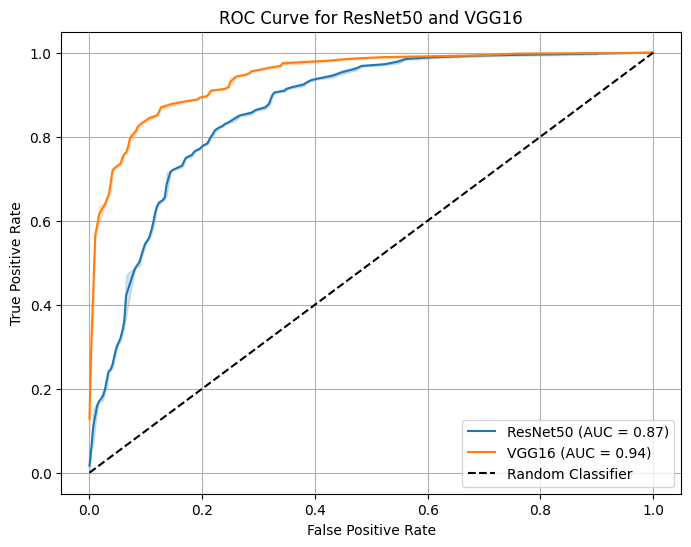

In [ ]:
# Calculate ROC curve for ResNet50
fpr_resnet, tpr_resnet, _ = roc_curve(resnet50_labels, resnet50_probs)

# Calculate ROC curve for VGG16
fpr_vgg, tpr_vgg, _ = roc_curve(vgg16_labels, vgg16_probs)

plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr_resnet, y=tpr_resnet, label=f'ResNet50 (AUC = {resnet50_metrics["AUC"]:.2f})')
sns.lineplot(x=fpr_vgg, y=tpr_vgg, label=f'VGG16 (AUC = {vgg16_metrics["AUC"]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for ResNet50 and VGG16')
plt.legend()
plt.grid(True)
plt.show()

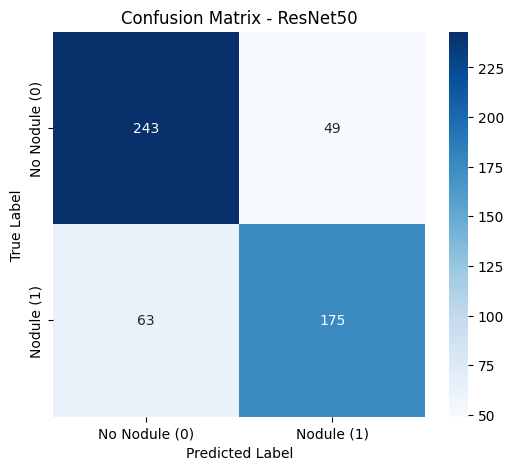

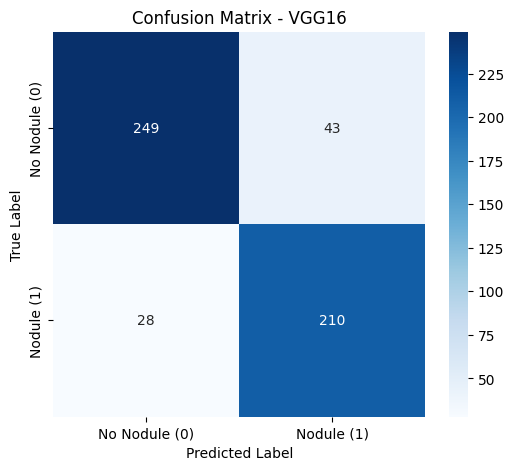

In [ ]:
def plot_confusion_matrix(cm, model_name):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Nodule (0)', 'Nodule (1)'],
                yticklabels=['No Nodule (0)', 'Nodule (1)'])
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

plot_confusion_matrix(resnet50_metrics['Confusion Matrix'], "ResNet50")
plot_confusion_matrix(vgg16_metrics['Confusion Matrix'], "VGG16")

In [ ]:
# Save results from models
def save_metrics_to_drive(model_metrics, threshold, name, save_dir):
    """ Save all metrics, thresholds and training history to Google Drive."""
    # Save metrics to text file
    metrics_df = pd.DataFrame([model_metrics])
    metrics_path = os.path.join(save_dir, f'{name}_test_metrics.txt')
    with open(metrics_path, 'w') as f:
        f.write("\nTest Set Metrics:\n")
        for key, value in model_metrics.items():
            f.write(f"  {key}: {value}\n")
    print(f"Test metrics saved to: {metrics_path}")

    # Save threshold to text file
    threshold_path = os.path.join(save_dir, f'{name}_threshold.txt')
    with open(threshold_path, 'w') as f:
        f.write(f"Model: {name}\n")
        f.write(f"Best threshold: {threshold:.4f}\n")
    print(f"Threshold saved to: {threshold_path}")


# ResNet50 model stats
save_metrics_to_drive(resnet50_metrics, resnet50_threshold, "ResNet50", results_dir)
# VGG16 model stats
save_metrics_to_drive(vgg16_metrics, vgg16_threshold, "VGG16", results_dir)

Test metrics saved to: /content/drive/MyDrive/Models/Results/ResNet50_test_metrics.txt
Threshold saved to: /content/drive/MyDrive/Models/Results/ResNet50_threshold.txt
Test metrics saved to: /content/drive/MyDrive/Models/Results/VGG16_test_metrics.txt
Threshold saved to: /content/drive/MyDrive/Models/Results/VGG16_threshold.txt


# XAI Implementation

Code sources:

Grad-CAM:
*   https://github.com/kaopanboonyuen/GradFaith-CAM/blob/main/gradcam/gradcam.py
*   https://github.com/nikhilroxtomar/GradCAM-in-PyTorch/blob/main/gradcam.py
*   https://medium.com/@stepanulyanin/implementing-grad-cam-in-pytorch-ea0937c31e82
*   https://medium.com/@stepanulyanin/grad-cam-for-resnet152-network-784a1d65f3
*   https://github.com/FrancoisPorcher/grad-cam/blob/main/grad_cam.py


LIME:
*   https://github.com/suryansh-raghuvanshi-data/Model-Explainbility/blob/main/Lime_Shap.ipynb
*   https://www.kaggle.com/code/prashant111/explain-your-model-predictions-with-lime
*   https://github.com/marcotcr/lime

SHAP:
* https://shap.readthedocs.io/en/latest/generated/shap.GradientExplainer.html#shap.GradientExplainer
* https://shap.readthedocs.io/en/latest/example_notebooks/image_examples/image_classification/Explain%20an%20Intermediate%20Layer%20of%20VGG16%20on%20ImageNet%20%28PyTorch%29.html



## Setup for XAI

In [ ]:
X_test = np.load(x_test_path)
y_test = np.load(y_test_path)
m_test = np.load(m_test_path)

## Grad-CAM Class







In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handlers = []

        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]

        self.handlers.append(self.target_layer.register_forward_hook(forward_hook))
        self.handlers.append(self.target_layer.register_full_backward_hook(backward_hook))

    def generate_heatmap(self, input_tensor):
        self.model.eval()

        # Forward pass
        output = self.model(input_tensor)

        # Backward pass (Backpropagating directly through the single output node)
        self.model.zero_grad()
        loss = output[0, 0]
        loss.backward()

        # Compute weights from gradients
        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]
        weights = np.mean(gradients, axis=(1, 2))

        # Weighted sum of activations
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * activations[i]

        # Apply ReLU and normalise - only focus on features that positively contribute to prediction
        cam = np.maximum(cam, 0)
        if cam.max() != 0:
            cam = cam / cam.max()

        cam = cv2.resize(cam, (input_tensor.shape[2], input_tensor.shape[3]))
        return cam, output.item() # Returns heatmap and the raw prediction score

    def remove_hooks(self):
        for handler in self.handlers:
            handler.remove()

# Helper function to overlay heatmap on the grayscale slice
def overlay_heatmap(img, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    img_rgb = (img * 255).astype(np.uint8)
    if len(img_rgb.shape) == 2 or img_rgb.shape[2] == 1:
        img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_GRAY2RGB)

    heatmap_colored = cv2.applyColorMap((heatmap * 255).astype(np.uint8), colormap)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    overlayed = cv2.addWeighted(img_rgb, 1 - alpha, heatmap_colored, alpha, 0)
    return overlayed

## LIME Class - Wrapper Function for Conversion to NumPy Image (RGB format)



In [ ]:
# Initialise the LIME Image Explainer
explainer = lime_image.LimeImageExplainer()

# Define a unified prediction wrapper for LIME
# LIME passes a batch of NumPy images (NHWC format, values 0-255 or 0-1)
def get_lime_predict_fn(model, device):

    def predict_fn(images):
        model.eval()

        # LIME gives NHWC
        batch_tensor = torch.tensor(images, dtype=torch.float32, device=device)

        # NHWC -> NCHW
        batch_tensor = batch_tensor.permute(0, 3, 1, 2)

        # Same normalisation used during training
        mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)

        std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

        batch_tensor = (batch_tensor - mean) / std

        with torch.no_grad():
            logits = model(batch_tensor)
            probs = torch.sigmoid(logits)

        pos_prob = probs.cpu().numpy().reshape(-1, 1)
        neg_prob = 1.0 - pos_prob

        return np.hstack((neg_prob, pos_prob))

    return predict_fn

# Create prediction wrappers for both models
predict_fn_resnet = get_lime_predict_fn(resnet50, device)
predict_fn_vgg = get_lime_predict_fn(vgg16, device)

## SHAP

In [ ]:
# Define background reference batch
background = torch.zeros(5, 3, 224, 224, device=device)

# Initialise the Gradient Explainer
explainer_resnet = shap.GradientExplainer(resnet50, background)
explainer_vgg = shap.GradientExplainer(vgg16, background)

def get_shap_image(model, input_tensor):
    explainer = shap.GradientExplainer(model, background)

    shap_values, = explainer.shap_values(input_tensor, ranked_outputs=1)[0]

    if isinstance(shap_values, torch.Tensor):
        shap_values = shap_values.detach().cpu().numpy()

    shap_values = np.asarray(shap_values)
    shap_values = np.squeeze(shap_values)

    # We want (C, H, W)
    if shap_values.ndim == 3:
        # (C, H, W)
        shap_map = np.mean(shap_values, axis=0)

    elif shap_values.ndim == 2:
        # Already (H, W)
        shap_map = shap_values

    else:
        raise ValueError(
            f"Unexpected SHAP shape: {shap_values.shape}"
        )

    if shap_map.ndim != 2:
        raise ValueError(
            f"SHAP map must be 2D, got shape {shap_map.shape}"
        )

    return shap_map.astype(np.float32)

# Helper to determine colour limits dynamically based on max attribution magnitude
def get_vmin_vmax(shap_map):
    max_val = np.max(np.abs(shap_map))
    return -max_val, max_val

# Helper function for consistent plotting of attributions
def plot_attribution(ax, img, attr_map, title, cmap=None, vmin=None, vmax=None):
    ax.imshow(img, cmap='gray')
    # Overlay attribution map with transparency.
    im = ax.imshow(attr_map, cmap=cmap, alpha=0.6, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=12)
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

## Wrapper Functions for Retrieving XAI Outputs

In [ ]:
# Grad-CAM Wrapper
def get_gradcam_map(model, img_tensor):
    """Generates a Grad-CAM heatmap and prediction score."""
    # Directly target the layers on the already-loaded variables
    target_layer = (
        model.layer4[-1] if hasattr(model, "layer4") else model.features[-1]
    )
    cam = GradCAM(model, target_layer)
    heatmap, score = cam.generate_heatmap(img_tensor)
    cam.remove_hooks()
    return heatmap, score


# LIME Wrapper
def get_lime_map(model, raw_img, num_samples=500):
    """Generates a LIME mask for positive contributions (label=1)."""
    lime_input_img = np.stack([raw_img, raw_img, raw_img], axis=-1).astype(
        np.float64
    )
    predict_fn = (
        predict_fn_resnet if hasattr(model, "layer4") else predict_fn_vgg
    )

    # Generate explanations (hide_color=0 replaces superpixels with black)
    explanation = explainer.explain_instance(
        lime_input_img,
        predict_fn,
        labels=(0, 1), # Forces calculation for both positive and negative classes
        top_labels=2,
        hide_color=0,
        num_samples=num_samples # Number of random pertubations to try
    )

    # Extract the boundaries showing positive contributions (label 1 = Nodule)
    # positive_only=True means we only show patches that increased nodule probability
     # Take top 5 most important regions
    temp, mask = explanation.get_image_and_mask(
        label=1, positive_only=True, num_features=5, hide_rest=False
    )
    return temp, mask

def get_lime_importance_map(model, raw_img, num_samples=500):
    """Generates a LIME importance map."""

    lime_input_img = np.stack(
        [raw_img, raw_img, raw_img],
        axis=-1
    ).astype(np.float64)

    predict_fn = (
        predict_fn_resnet if hasattr(model, "layer4") else predict_fn_vgg
    )

    explanation = explainer.explain_instance(
        lime_input_img,
        predict_fn,
        labels=(0, 1),
        top_labels=2,
        hide_color=0,
        num_samples=num_samples
    )

    # Return the positive LIME weights for the nodule class
    local_exp = explanation.local_exp[1]

    # Create an empty importance map
    importance_map = np.zeros(
        explanation.segments.shape,
        dtype=np.float32
    )

    # Insert each superpixel's LIME importance
    for segment_id, weight in local_exp:
        if weight > 0:
            importance_map[
                explanation.segments == segment_id
            ] = weight

    return importance_map

# SHAP Wrapper
def get_shap_map(model, img_tensor):
    """Generates a 2D SHAP importance map."""
    return get_shap_image(model, img_tensor)

## Running XAI Methods on Set of Images

In [ ]:
# Select 10 images from the test set
sample_indices = [25, 59, 75, 121, 230, 199, 340, 200, 265, 300]

# Store results
resnet_results = []
vgg_results = []

for sample_idx in sample_indices:

    print(f"Processing image {sample_idx}")

    # Load image, label and ground-truth mask
    raw_img = X_test[sample_idx]
    label = y_test[sample_idx]
    gt_mask = m_test[sample_idx]

    # Prepare image tensor
    # Convert grayscale to 3 channels for ResNet/VGG
    img_tensor = (torch.tensor(raw_img, dtype=torch.float32).unsqueeze(0).unsqueeze(0).repeat(1, 3, 1, 1).to(device))

    # RESNET-50
    # Grad-CAM
    heatmap_res, score_res = get_gradcam_map(resnet50, img_tensor)
    overlay_res = overlay_heatmap(raw_img, heatmap_res)

    # Convert logit to probability
    prob_res = torch.sigmoid(torch.tensor(score_res)).item() * 100

    # LIME
    temp_res, mask_res = get_lime_map(resnet50, raw_img, num_samples=500)

    # SHAP
    shap_res_img = get_shap_map(resnet50, img_tensor)

    # SHAP colour scale
    vmin_res, vmax_res = get_vmin_vmax(shap_res_img)

    # Save ResNet results
    resnet_results.append({
        "sample_idx": sample_idx,
        "raw_img": raw_img,
        "label": label,
        "gt_mask": gt_mask,
        "overlay": overlay_res,
        "temp_lime": temp_res,
        "mask_lime": mask_res,
        "shap": shap_res_img,
        "vmin": vmin_res,
        "vmax": vmax_res,
        "prob": prob_res
    })


    # VGG-16
    # Grad-CAM
    heatmap_vgg, score_vgg = get_gradcam_map(vgg16, img_tensor)
    overlay_vgg = overlay_heatmap(raw_img, heatmap_vgg)

    # Convert logit to probability
    prob_vgg = torch.sigmoid(torch.tensor(score_vgg)).item() * 100

    # LIME
    temp_vgg, mask_vgg = get_lime_map(vgg16,raw_img, num_samples=500)

    # SHAP
    shap_vgg_img = get_shap_map(vgg16, img_tensor)

    # SHAP colour scale
    vmin_vgg, vmax_vgg = get_vmin_vmax(shap_vgg_img)

    # Save VGG results
    vgg_results.append({
        "sample_idx": sample_idx,
        "raw_img": raw_img,
        "label": label,
        "gt_mask": gt_mask,
        "overlay": overlay_vgg,
        "temp_lime": temp_vgg,
        "mask_lime": mask_vgg,
        "shap": shap_vgg_img,
        "vmin": vmin_vgg,
        "vmax": vmax_vgg,
        "prob": prob_vgg
    })


print("Finished processing all 10 images.")

Processing image 25


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Processing image 59


  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

Processing image 300


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Finished processing all 10 images.


## Displaying XAI Visualisations

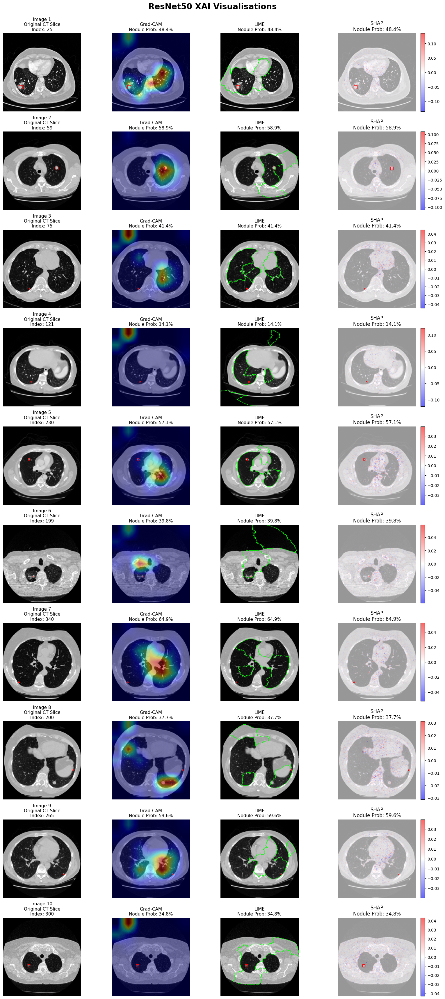

In [ ]:
# Displaying ResNet-50 Results

fig, axes = plt.subplots(10, 4, figsize=(16, 35))

fig.suptitle(
    "ResNet50 XAI Visualisations",
    fontsize=20,
    weight='bold'
)

for row, result in enumerate(resnet_results):

    raw_img = result["raw_img"]
    label = result["label"]
    gt_mask = result["gt_mask"]
    prob = result["prob"]

    # Original CT Slice
    axes[row, 0].imshow(
        raw_img,
        cmap='gray'
    )

    axes[row, 0].set_title(
        f"Image {row + 1}\nOriginal CT Slice\n"
        f"Index: {result['sample_idx']}",
        fontsize=11
    )

    axes[row, 0].axis('off')


    # Grad-CAM
    axes[row, 1].imshow(
        result["overlay"]
    )

    axes[row, 1].set_title(
        f"Grad-CAM\nNodule Prob: {prob:.1f}%",
        fontsize=11
    )

    axes[row, 1].axis('off')


    # LIME
    axes[row, 2].imshow(
        mark_boundaries(
            result["temp_lime"],
            result["mask_lime"],
            color=(0, 1, 0)
        )
    )

    axes[row, 2].set_title(
        f"LIME\nNodule Prob: {prob:.1f}%",
        fontsize=11
    )

    axes[row, 2].axis('off')


    # SHAP
    plot_attribution(
        axes[row, 3],
        raw_img,
        result["shap"],
        f"SHAP\nNodule Prob: {prob:.1f}%",
        cmap='bwr',
        vmin=result["vmin"],
        vmax=result["vmax"]
    )


    # Ground-truth bounding box
    if label == 1 and gt_mask is not None and np.any(gt_mask > 0):

        y_indices, x_indices = np.where(gt_mask > 0)

        y_min, y_max = y_indices.min(), y_indices.max()
        x_min, x_max = x_indices.min(), x_indices.max()

        width = x_max - x_min + 1
        height = y_max - y_min + 1

        for ax in axes[row, :]:
            rect = patches.Rectangle(
                (x_min, y_min),
                width,
                height,
                linewidth=1,
                edgecolor='red',
                facecolor='none',
                linestyle='-'
            )

            ax.add_patch(rect)


plt.tight_layout()
plt.subplots_adjust(
    top=0.95
)

plt.show()

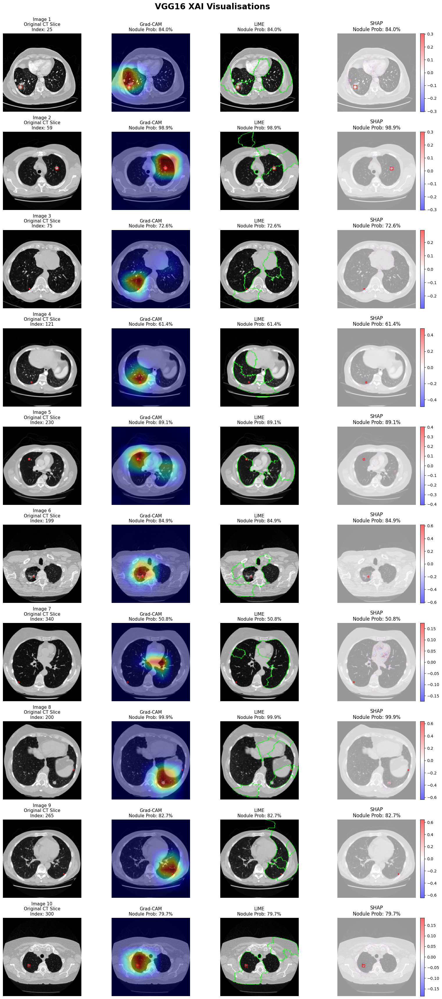

In [ ]:
# Display VGG-16 Results
fig, axes = plt.subplots(10, 4, figsize=(16, 35))

fig.suptitle(
    "VGG16 XAI Visualisations",
    fontsize=20,
    weight='bold'
)

for row, result in enumerate(vgg_results):

    raw_img = result["raw_img"]
    label = result["label"]
    gt_mask = result["gt_mask"]
    prob = result["prob"]

    # Original CT Slice
    axes[row, 0].imshow(
        raw_img,
        cmap='gray'
    )

    axes[row, 0].set_title(
        f"Image {row + 1}\nOriginal CT Slice\n"
        f"Index: {result['sample_idx']}",
        fontsize=11
    )

    axes[row, 0].axis('off')


    # Grad-CAM
    axes[row, 1].imshow(
        result["overlay"]
    )

    axes[row, 1].set_title(
        f"Grad-CAM\nNodule Prob: {prob:.1f}%",
        fontsize=11
    )

    axes[row, 1].axis('off')


    # LIME
    axes[row, 2].imshow(
        mark_boundaries(
            result["temp_lime"],
            result["mask_lime"],
            color=(0, 1, 0)
        )
    )

    axes[row, 2].set_title(
        f"LIME\nNodule Prob: {prob:.1f}%",
        fontsize=11
    )

    axes[row, 2].axis('off')


    # SHAP
    plot_attribution(
        axes[row, 3],
        raw_img,
        result["shap"],
        f"SHAP\nNodule Prob: {prob:.1f}%",
        cmap='bwr',
        vmin=result["vmin"],
        vmax=result["vmax"]
    )


    # Ground-truth bounding box
    if label == 1 and gt_mask is not None and np.any(gt_mask > 0):

        y_indices, x_indices = np.where(gt_mask > 0)

        y_min, y_max = y_indices.min(), y_indices.max()
        x_min, x_max = x_indices.min(), x_indices.max()

        width = x_max - x_min + 1
        height = y_max - y_min + 1

        for ax in axes[row, :]:
            rect = patches.Rectangle(
                (x_min, y_min),
                width,
                height,
                linewidth=1,
                edgecolor='red',
                facecolor='none',
                linestyle='-'
            )

            ax.add_patch(rect)


plt.tight_layout()
plt.subplots_adjust(
    top=0.95
)

plt.show()

# XAI Evaluation

Separarating the slices into TP, FP, TN, FN:
1. Localisation accuracy/IoU set (also used for Pointing Game) - TP, FN  since IoU is undefined if there are no true labels/annotations (annotations also required for Pointing Game)
2. Fidelity/AUC set - positive predictions (TP and FP to see the confidence changes i.e. if the model was pointing to the correct area or irrelevant tissue)
3. Consistency/SSIM set - all slices (the predictions should not change when input altered, thus all slices are suitable)

In [ ]:
def build_xai_evaluation_sets(model, X_test, m_test, device, threshold):
    """
    Categorises test indices into TP, FP, FN, and TN buckets using X_test and m_test.
    Constructs the index sets for Accuracy IoU, Fidelity AUC and Consistency SSIM.
    """
    model.eval()

    tp_indices, fp_indices, fn_indices, tn_indices = [], [], [], []

    print("Building XAI evaluation subsets from X_test and m_test:")

    with torch.no_grad():
        for idx in range(len(X_test)):
            # Check ground-truth presence from m_test
            gt_mask = m_test[idx]
            has_nodule = (np.sum(gt_mask) > 0)

            # Prepare image tensor from X_test
            img = X_test[idx]
            if isinstance(img, np.ndarray):
                img_tensor = torch.from_numpy(img).float()
            else:
                img_tensor = img.float()

            # Ensure shape is [1, 3, 224, 224]
            if img_tensor.ndim == 2:  # [H, W]
                img_tensor = img_tensor.unsqueeze(0).repeat(3, 1, 1).unsqueeze(0)
            elif img_tensor.ndim == 3:  # [C, H, W]
                img_tensor = img_tensor.unsqueeze(0)

            normalize = transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )

            img_tensor = normalize(img_tensor.squeeze(0)).unsqueeze(0)

            img_tensor = img_tensor.to(device)

            # Model inference
            logit = model(img_tensor)
            prob = torch.sigmoid(logit).item()
            pred_positive = (prob >= threshold)

            # Categorise index
            if has_nodule and pred_positive:
                tp_indices.append(idx)
            elif not has_nodule and pred_positive:
                fp_indices.append(idx)
            elif has_nodule and not pred_positive:
                fn_indices.append(idx)
            else:
                tn_indices.append(idx)

    # Construct metric-specific sets
    iou_set = tp_indices + fn_indices            # TP + FN
    auc_set = tp_indices + fp_indices            # TP + FP
    consistency_set = tp_indices + fp_indices + fn_indices + tn_indices  # All

    print(f"\nCategorisation Complete:")
    print(f"  TP: {len(tp_indices)} | FP: {len(fp_indices)} | FN: {len(fn_indices)} | TN: {len(tn_indices)}")
    print(f"  - IoU Set (TP + FN)        : {len(iou_set)} samples")
    print(f"  - Fidelity AUC Set (TP + FP): {len(auc_set)} samples")
    print(f"  - Consistency Set (All)    : {len(consistency_set)} samples\n")

    return {
        'tp_indices': tp_indices,
        'fp_indices': fp_indices,
        'fn_indices': fn_indices,
        'tn_indices': tn_indices,
        'iou_set': iou_set,
        'auc_set': auc_set,
        'consistency_set': consistency_set
    }

1. Grad-CAM: heatmap_res / heatmap_vgg is already a 2D numpy array normalized to $[0, 1]$.

2. LIME: mask_res / mask_vgg is a binary/integer 2D superpixel mask.

3. SHAP: shap_res_img / shap_vgg_img contains both positive and negative attributions. To evaluate where the model focuses on the nodule, we apply ReLU (keeping positive attributions) and normalize to $[0, 1]$.


In [ ]:
imagenet_normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

def normalise_map(heatmap_array: np.ndarray) -> np.ndarray:
    """
    Core normalisation process:
    1. Converts tensor inputs to NumPy if necessary.
    2. Applies ReLU to focus on positive contributions.
    3. Min-Max normalises the array to [0.0, 1.0].
    Returns a NumPy float32 array.
    """
    # Convert from numpy if needed
    if isinstance(heatmap_array, torch.Tensor):
        heatmap_array = heatmap_array.detach().cpu().numpy()

    # Apply ReLU (zero out negative attributions)
    heatmap_array = np.maximum(heatmap_array, 0)

    # Min-Max Normalisation to [0, 1]
    h_min, h_max = heatmap_array.min(), heatmap_array.max()
    if h_max - h_min < 1e-8:
        return np.zeros_like(heatmap_array, dtype=np.float32)

    return ((heatmap_array - h_min) / (h_max - h_min + 1e-8)).astype(np.float32)


def get_tensor(img):
    """
    Converts a 224x224 grayscale LUNA slice into
    the same 3-channel, ImageNet-normalized tensor
    used during model training.

    Returns:
        Tensor of shape [1, 3, 224, 224]
    """

    if isinstance(img, np.ndarray):
        t = torch.from_numpy(img).float()
    else:
        t = img.float()

    # [H, W] -> [1, 3, H, W]
    if t.ndim == 2:
        t = t.unsqueeze(0).repeat(3, 1, 1).unsqueeze(0)

    # [C, H, W] -> [1, C, H, W]
    elif t.ndim == 3:
        t = t.unsqueeze(0)

    # Apply the same normalisation used during training
    t = imagenet_normalize(t.squeeze(0)).unsqueeze(0)

    return t.to(device)


## Localisation Accuracy via IoU using sklearn.metrics



*   Jaccard Score Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.jaccard_score.html



In [ ]:
def compute_xai_iou(heatmap_2d: np.ndarray, gt_mask_2d: np.ndarray, threshold: float = 0.5) -> float:
    """
    Computes IoU (Jaccard Index) between a normalised XAI heatmap and expert nodule mask.
    Target Slices: True Positives (TP) and False Negatives (FN).
    """
    # Binarise the explanation heatmap
    heatmap_bin = (heatmap_2d >= threshold).astype(np.uint8)

    # Binarise ground truth mask (ensure 0 or 1)
    gt_bin = (gt_mask_2d > 0).astype(np.uint8)

    # Calculate Jaccard Score (IoU) on flattened arrays
    iou = jaccard_score(gt_bin.flatten(), heatmap_bin.flatten(), zero_division=0.0)

    return float(iou)

def compute_topk_iou(heatmap_2d, gt_mask_2d, top_percent=10):
    """
    IoU using the top X% most important XAI pixels.
    """
    # Binarise ground truth mask (ensure 0 or 1)
    gt_bin = (gt_mask_2d > 0).astype(np.uint8)

    # Select top X% of XAI pixels
    threshold = np.percentile(heatmap_2d, 100 - top_percent)

    # Binarise the explanation heatmap
    heatmap_bin = (heatmap_2d >= threshold).astype(np.uint8)

    # Calculate Jaccard Score (IoU) on flattened arrays
    iou = jaccard_score(gt_bin.flatten(), heatmap_bin.flatten(), zero_division=0.0)

    return iou


def run_localisation_eval(model, iou_indices, X_test, m_test, device):
    print(f"\nRunning Localisation Accuracy (IoU)")
    iou_results = {"Grad-CAM": [], "LIME": [], "SHAP": []}

    for idx in iou_indices:
        img_tensor = get_tensor(X_test[idx])
        raw_img = X_test[idx]
        gt_mask = m_test[idx]

        # get_gradcam_map returns (heatmap, score) -> extract heatmap [0]
        gc_map, _ = get_gradcam_map(model, img_tensor)
        map_gc = normalise_map(gc_map)

        # get_lime_map returns (temp, mask) -> extract mask [1]
        _, lime_mask = get_lime_map(model, raw_img)
        map_lime = normalise_map(lime_mask)

        # SHAP returns 2D array directly
        shap_map = get_shap_map(model, img_tensor)
        map_shap = normalise_map(shap_map)

        # Compute IoU - call the relevant method (either baseline method or top-k)
        iou_results["Grad-CAM"].append(
            compute_topk_iou(map_gc, gt_mask)
        )
        iou_results["LIME"].append(
            compute_topk_iou(map_lime, gt_mask)
        )
        iou_results["SHAP"].append(
            compute_topk_iou(map_shap, gt_mask)
        )

    return iou_results

## Fidelity via AUC using sklearn.metrics


*   AUC Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.auc.html


* Method adapted from the following implementation: https://github.com/Kevin0304-li/lightweight-explainability/blob/main/evaluation_metrics.py


In [ ]:
def compute_deletion_auc(model, img_tensor, heatmap, device, steps=10):
    """
    Evaluates Fidelity via Area Under the Deletion Curve (AUC).

    The most important pixels according to the XAI heatmap are
    progressively removed. After each deletion step, the model's
    positive-class probability is recorded.

    Returned Deletion AUC Score
    Lower Deletion AUC -> faster reduction in model confidence -> greater fidelity
    """

    # Normalise heatmap to [0, 1]
    heatmap = normalise_map(heatmap)

    original_img = img_tensor.detach().cpu().clone()

    mean_color = original_img.mean(dim=(2, 3))

    # Original model prediction
    with torch.no_grad():
        original_logit = model(img_tensor.to(device))
        original_prob = torch.sigmoid(original_logit).item()

    flat_heatmap = heatmap.flatten()

    # Sort pixels from most important to least important
    sorted_indices = np.argsort(flat_heatmap)[::-1]

    num_pixels = flat_heatmap.size

    # Number of pixels removed at each step
    pixels_per_step = max(1, num_pixels // steps)

    deletion_fractions = [0.0]
    probabilities = [original_prob]

    # Progressively remove important pixels
    for step in range(1, steps + 1):

        num_to_delete = min(
            step * pixels_per_step,
            num_pixels
        )

        pixels_to_delete = sorted_indices[:num_to_delete]

        rows, cols = np.unravel_index(
            pixels_to_delete,
            heatmap.shape
        )

        # Start from the original image at every step
        deleted_img = original_img.clone()

        # Delete selected pixels
        deleted_img[0, 0, rows, cols] = mean_color[0, 0]
        deleted_img[0, 1, rows, cols] = mean_color[0, 1]
        deleted_img[0, 2, rows, cols] = mean_color[0, 2]

        # Model prediction after deletion
        with torch.no_grad():
            logit = model(deleted_img.to(device))
            prob = torch.sigmoid(logit).item()

        fraction_deleted = num_to_delete / num_pixels

        deletion_fractions.append(fraction_deleted)
        probabilities.append(prob)

    # Calculate area under the deletion curve
    deletion_auc = auc(
        deletion_fractions,
        probabilities
    )

    return float(deletion_auc), deletion_fractions, probabilities

def run_auc_eval(model, auc_indices, X_test, device, steps=10):
    """
    Runs Deletion AUC Fidelity evaluation for Grad-CAM, LIME and SHAP
    across the specified image set.
    """

    print("\nRunning Deletion AUC Evaluation")

    deletion_results = {
        "Grad-CAM": [],
        "LIME": [],
        "SHAP": []
    }

    for idx in auc_indices:

        img_tensor = get_tensor(X_test[idx])
        raw_img = X_test[idx]

        # Grad-CAM
        gc_map, _ = get_gradcam_map(model, img_tensor)
        map_gc = normalise_map(gc_map)

        gc_score, _, _ = compute_deletion_auc(
            model=model,
            img_tensor=img_tensor,
            heatmap=map_gc,
            device=device,
            steps=steps
        )

        deletion_results["Grad-CAM"].append(gc_score)

        # LIME
        lime_map = get_lime_importance_map(model, raw_img)
        map_lime = normalise_map(lime_map)

        lime_score, _, _ = compute_deletion_auc(
            model=model,
            img_tensor=img_tensor,
            heatmap=map_lime,
            device=device,
            steps=steps
        )

        deletion_results["LIME"].append(lime_score)

        # SHAP
        shap_map = get_shap_map(model, img_tensor)
        map_shap = normalise_map(shap_map)

        shap_score, _, _ = compute_deletion_auc(
            model=model,
            img_tensor=img_tensor,
            heatmap=shap_map,
            device=device,
            steps=steps
        )

        deletion_results["SHAP"].append(shap_score)

    return deletion_results

## Consistency via SSIM using skimage.metrics



*   SSIM Documentation:
1. https://scikit-image.org/docs/0.25.x/api/skimage.metrics.html#skimage.metrics.structural_similarity
2. https://scikit-image.org/docs/0.25.x/auto_examples/transform/plot_ssim.html
*   Why we used noise:
1. https://arxiv.org/html/2506.13917v1#S3
2. https://github.com/behnamasadi/robotic_notes/blob/master/docs/ssim.ipynb
3. https://github.com/Kevin0304-li/lightweight-explainability/blob/main/evaluation_metrics.py





In [ ]:
def extract_heatmap(xai_output):
    """Unpacks tuples and converts PyTorch CUDA tensors to CPU NumPy arrays."""
    # Unpack tuples if returned
    if isinstance(xai_output, tuple):
        # LIME returns (temp, mask) where temp is a 3D image [H, W, C]
        if isinstance(xai_output[0], np.ndarray) and xai_output[0].ndim == 3:
            xai_output = xai_output[1]
        else:
            xai_output = xai_output[0]

    # Convert GPU PyTorch Tensor to CPU NumPy Array
    if isinstance(xai_output, torch.Tensor):
        xai_output = xai_output.detach().cpu().numpy()

    return xai_output


def compute_xai_ssim(model, img_input, explain_fn, device: torch.device, noise_std: float = 0.02) -> float:
    """Computes Structural Similarity Index (SSIM) between baseline explanation
    and explanation on a noisy image/tensor.
    """
    # Generate baseline explanation
    map_orig = extract_heatmap(explain_fn(model, img_input))
    map_orig = normalise_map(map_orig)  # Range [0.0, 1.0]

    # Add Gaussian noise based on input type
    if isinstance(img_input, torch.Tensor):
        noise = torch.randn_like(img_input) * noise_std
        noisy_input = img_input + noise
    else:
        noise = np.random.normal(0, noise_std, img_input.shape).astype(
            img_input.dtype
        )
        noisy_input = img_input + noise

    # Generate perturbed explanation
    map_noisy = extract_heatmap(explain_fn(model, noisy_input))
    map_noisy = normalise_map(map_noisy)  # Range [0.0, 1.0]

    # Compute SSIM
    score = ssim(map_orig, map_noisy, data_range=1.0)

    return float(score)


def run_consistency_eval(model, ssim_indices, X_test, device):
    print(f"\nRunning Consistency (SSIM)")
    ssim_results = {"Grad-CAM": [], "LIME": [], "SHAP": []}

    for idx in ssim_indices:
        img_tensor = get_tensor(X_test[idx])
        raw_img = X_test[idx]

        # Compute SSIM under Gaussian noise perturbation
        ssim_results["Grad-CAM"].append(
            compute_xai_ssim(model, img_tensor, get_gradcam_map, device)
        )
        ssim_results["LIME"].append(
            compute_xai_ssim(model, raw_img, get_lime_map, device)
        )
        ssim_results["SHAP"].append(
            compute_xai_ssim(model, img_tensor, get_shap_map, device)
        )

    return ssim_results

## Pointing Game

Adapted from the following TorchRay implementation: https://github.com/facebookresearch/TorchRay/tree/master/torchray





In [ ]:
def compute_pointing_game(gt_mask, heatmap, tolerance=15):
    """
    Determine whether a circular tolerance region around the
    maximum positive attribution point overlaps the ground-truth bounding box
    region.

    Returns 1 for a hit or 0 for a miss
    """
    # Ensure arrays are NumPy arrays
    heatmap_2d = np.asarray(heatmap)
    gt_mask_2d = np.asarray(gt_mask)

    # Keep only positive attribution
    heatmap_2d = np.maximum(heatmap_2d, 0)

    # Find the location of maximum attribution
    max_y, max_x = np.unravel_index(
        np.argmax(heatmap_2d),
        heatmap_2d.shape
    )

    # Ground-truth mask
    gt_mask = gt_mask_2d > 0

    # Create coordinate grid
    y, x = np.ogrid[:gt_mask.shape[0], :gt_mask.shape[1]]

    # Tolerance region around maximum attribution point
    tolerance_region = ((x - max_x) ** 2 + (y - max_y) ** 2) < tolerance ** 2

    # Hit if tolerance region overlaps ground-truth mask
    hit = np.any(gt_mask & tolerance_region)

    return int(hit)

def run_pointing_game_eval(model, pointing_indices, X_test, m_test, device):
    print("\nRunning Pointing Game Evaluation")

    pointing_results = {
        "Grad-CAM": [],
        "LIME": [],
        "SHAP": []
    }

    for idx in pointing_indices:

        img_tensor = get_tensor(X_test[idx])
        raw_img = X_test[idx]
        gt_mask = m_test[idx]

        gc_map, _ = get_gradcam_map(model, img_tensor)
        map_gc = normalise_map(gc_map)

        lime_map= get_lime_importance_map(model, raw_img)
        map_lime = normalise_map(lime_map)

        shap_map = get_shap_map(model, img_tensor)
        shap_map = np.maximum(shap_map, 0)
        map_shap = normalise_map(shap_map)

        pointing_results["Grad-CAM"].append(
            compute_pointing_game(gt_mask, map_gc, 1)
        )
        pointing_results["LIME"].append(
            compute_pointing_game(gt_mask, map_lime, 1)
        )
        pointing_results["SHAP"].append(
            compute_pointing_game(gt_mask, map_shap, 1)
        )

    return pointing_results


In [ ]:
# Printing function
def print_xai_results(model_name, iou_results=None, auc_results=None, ssim_results=None):
    print(f"\n{'=' * 50}")
    print(f"{model_name} XAI RESULTS")
    print(f"{'=' * 50}")


    if iou_results is not None:
        print("\nLocalisation Accuracy (IoU)")
        print("-" * 35)

        for method, scores in iou_results.items():
            if len(scores) > 0:
                print(f"{method:<10}: {np.mean(scores):.4f}")
            else:
                print(f"{method:<10}: No results")

    if auc_results is not None:
        print("\nFidelity (Deletion AUC)")
        print("-" * 35)

        for method, scores in auc_results.items():
            if len(scores) > 0:
                print(f"{method:<10}: {np.mean(scores):.4f}")
            else:
                print(f"{method:<10}: No results")

    if ssim_results is not None:
        print("\nConsistency (SSIM)")
        print("-" * 35)

        for method, scores in ssim_results.items():
            if len(scores) > 0:
                print(f"{method:<10}: {np.mean(scores):.4f}")
            else:
                print(f"{method:<10}: No results")

    print(f"{'=' * 50}")

## Evaluation Script Order:
1. Localisation accuracy, fidelity and consistency for both models on only the true positive (TP) slices
2. Localisation accuracy for both models on only the false negative (FN) slices. This was performed using a threshold of 0.5 for the baseline, and then a top k% threshold was used in further experiments
3. Fidelity for both models on only the false positive (FP) slices
4. Localisation accuracy, fidelity and consistency for ResNet-50 using designated sets (TP + FN, TP + FP, and TP + FP + FN + TN, respectively)
5. Localisation accuracy, fidelity and consistency for VGG-16 using designated sets (TP + FN, TP + FP, and TP + FP + FN + TN, respectively)
6. Pointing Game for ResNet-50 on TP, FN and TP + FP + FN + TN
7. Pointing Game for VGG-16 on TP, FN and TP + FP + FN + TN
8. Pointing Game (0 tolerence) for ResNet-50 on TP, FN and TP + FP + FN + TN
9. Pointing Game (0 tolerence) for VGG-16 on TP, FN and TP + FP + FN + TN
10. Printing results from all tests


---


Note that all results should be read from the final printing cells and not the cells where the metrics were calculated (due to multiple experiments).




In [ ]:
print("Evaluation on TP only")
res_eval_sets = build_xai_evaluation_sets(resnet50, X_test, m_test, device, threshold = resnet50_threshold)

res_iou_tp = run_localisation_eval(
    resnet50, res_eval_sets["tp_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_iou_tp.pkl"), "wb") as f:
    pickle.dump(res_iou_tp, f)

res_auc_tp = run_auc_eval(
    resnet50, res_eval_sets["tp_indices"], X_test, device
)
with open(os.path.join(evaluation_dir, "res_auc_tp.pkl"), "wb") as f:
    pickle.dump(res_auc_tp, f)

res_ssim_tp = run_consistency_eval(
    resnet50, res_eval_sets["tp_indices"], X_test, device
)
with open(os.path.join(evaluation_dir, "res_ssim_tp.pkl"), "wb") as f:
    pickle.dump(res_ssim_tp, f)

#print_xai_results("ResNet50",  iou_results=res_iou_tp, auc_results=res_auc_tp, ssim_results=res_ssim_tp)
print_xai_results("ResNet50",  iou_results=res_iou_tp, auc_results=None, ssim_results=None)

Evaluation on TP only
Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 175 | FP: 49 | FN: 63 | TN: 243
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 224 samples
  - Consistency Set (All)    : 530 samples


Running Localisation Accuracy (IoU)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


ResNet50 XAI RESULTS

Localisation Accuracy (IoU)
-----------------------------------
Grad-CAM  : 0.0043
LIME      : 0.0031
SHAP      : 0.0025


In [ ]:
print("Evaluation on TP only")
vgg_eval_sets = build_xai_evaluation_sets(vgg16, X_test, m_test, device, threshold = vgg16_threshold)

vgg_iou_tp = run_localisation_eval(
    vgg16, vgg_eval_sets["tp_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_iou_tp.pkl"), "wb") as f:
    pickle.dump(vgg_iou_tp, f)

vgg_auc_tp = run_auc_eval(
    vgg16, vgg_eval_sets["tp_indices"], X_test, device
)
with open(os.path.join(evaluation_dir, "vgg_auc_tp.pkl"), "wb") as f:
    pickle.dump(vgg_auc_tp, f)

vgg_ssim_tp = run_consistency_eval(
    vgg16, vgg_eval_sets["tp_indices"], X_test, device
)
with open(os.path.join(evaluation_dir, "vgg_ssim_tp.pkl"), "wb") as f:
    pickle.dump(vgg_ssim_tp, f)

#print_xai_results("VGG16", iou_results=vgg_iou_tp, auc_results=vgg_auc_tp, ssim_results=vgg_ssim_tp)
print_xai_results("VGG16", iou_results=vgg_iou_tp, auc_results=None, ssim_results=None)

Evaluation on TP only
Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 210 | FP: 43 | FN: 28 | TN: 249
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 253 samples
  - Consistency Set (All)    : 530 samples


Running Localisation Accuracy (IoU)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


VGG16 XAI RESULTS

Localisation Accuracy (IoU)
-----------------------------------
Grad-CAM  : 0.0069
LIME      : 0.0039
SHAP      : 0.0037


In [ ]:
print("IoU with FN")
res_eval_sets = build_xai_evaluation_sets(resnet50, X_test, m_test, device, threshold = resnet50_threshold)

res_iou_fn = run_localisation_eval(
    resnet50, res_eval_sets["fn_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_iou_fn.pkl"), "wb") as f:
    pickle.dump(res_iou_fn, f)

print_xai_results("ResNet50", iou_results=res_iou_fn, auc_results=None, ssim_results=None)

vgg_eval_sets = build_xai_evaluation_sets(vgg16, X_test, m_test, device, threshold = vgg16_threshold)

vgg_iou_fn = run_localisation_eval(
    vgg16, vgg_eval_sets["fn_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_iou_fn.pkl"), "wb") as f:
    pickle.dump(vgg_iou_fn, f)

print_xai_results("VGG16", iou_results=vgg_iou_fn, auc_results=None, ssim_results=None)

IoU with FN
Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 175 | FP: 49 | FN: 63 | TN: 243
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 224 samples
  - Consistency Set (All)    : 530 samples


Running Localisation Accuracy (IoU)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


VGG16 XAI RESULTS

Localisation Accuracy (IoU)
-----------------------------------
Grad-CAM  : 0.0018
LIME      : 0.0010
SHAP      : 0.0010


In [ ]:
print("AUC with FP")
res_eval_sets = build_xai_evaluation_sets(resnet50, X_test, m_test, device, threshold = resnet50_threshold)

res_auc_fp = run_auc_eval(
    resnet50, res_eval_sets["fp_indices"], X_test, device
)
with open(os.path.join(evaluation_dir, "res_auc_fp.pkl"), "wb") as f:
    pickle.dump(res_auc_fp, f)

print_xai_results("ResNet50", iou_results=None, auc_results=res_auc_fp, ssim_results=None)

vgg_eval_sets = build_xai_evaluation_sets(vgg16, X_test, m_test, device, threshold = vgg16_threshold)

vgg_auc_fp = run_auc_eval(
    vgg16, vgg_eval_sets["fp_indices"], X_test, device
)
with open(os.path.join(evaluation_dir, "vgg_auc_fp.pkl"), "wb") as f:
    pickle.dump(vgg_auc_fp, f)

print_xai_results("VGG16", iou_results=None, auc_results=vgg_auc_fp, ssim_results=None)

AUC with FP

Running Deletion AUC Evaluation


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


VGG16 XAI RESULTS

Fidelity (Deletion AUC)
-----------------------------------
Grad-CAM  : 0.1670
LIME      : 0.2631
SHAP      : 0.2088


In [ ]:
print("Evaluation on full sets")
res_eval_sets = build_xai_evaluation_sets(resnet50, X_test, m_test, device, threshold = resnet50_threshold)

res_iou = run_localisation_eval(
    resnet50, res_eval_sets["iou_set"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_iou.pkl"), "wb") as f:
    pickle.dump(res_iou, f)

res_auc = run_auc_eval(
    resnet50, res_eval_sets["auc_set"], X_test, device
)
with open(os.path.join(evaluation_dir, "res_auc.pkl"), "wb") as f:
    pickle.dump(res_auc, f)


print_xai_results("ResNet50",  iou_results=res_iou, auc_results=res_auc, ssim_results=None)

Evaluation on full sets

Running Localisation Accuracy (IoU)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


ResNet50 XAI RESULTS

Localisation Accuracy (IoU)
-----------------------------------
Grad-CAM  : 0.0043
LIME      : 0.0030
SHAP      : 0.0024


In [ ]:
print("Evaluation on full sets")
res_eval_sets = build_xai_evaluation_sets(resnet50, X_test, m_test, device, threshold = resnet50_threshold)

res_ssim = run_consistency_eval(
    resnet50, res_eval_sets["consistency_set"], X_test, device
)
with open(os.path.join(evaluation_dir, "res_ssim.pkl"), "wb") as f:
    pickle.dump(res_ssim, f)

print_xai_results("ResNet50",  iou_results=None, auc_results=None, ssim_results=res_ssim)

Evaluation on full sets
Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 175 | FP: 49 | FN: 63 | TN: 243
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 224 samples
  - Consistency Set (All)    : 530 samples


Running Consistency (SSIM)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


ResNet50 XAI RESULTS

Consistency (SSIM)
-----------------------------------
Grad-CAM  : 0.7587
LIME      : 0.7520
SHAP      : 0.6841


In [ ]:
print("Evaluation on full sets")
vgg_eval_sets = build_xai_evaluation_sets(vgg16, X_test, m_test, device, threshold = vgg16_threshold)

vgg_iou = run_localisation_eval(
    vgg16, vgg_eval_sets["iou_set"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_iou.pkl"), "wb") as f:
    pickle.dump(vgg_iou, f)

vgg_auc = run_auc_eval(
    vgg16, vgg_eval_sets["auc_set"], X_test, device
)
with open(os.path.join(evaluation_dir, "vgg_auc.pkl"), "wb") as f:
    pickle.dump(vgg_auc, f)

vgg_ssim = run_consistency_eval(
    vgg16, vgg_eval_sets["consistency_set"], X_test, device
)
with open(os.path.join(evaluation_dir, "vgg_ssim.pkl"), "wb") as f:
    pickle.dump(vgg_ssim, f)


print_xai_results("VGG16", iou_results=vgg_iou, auc_results=vgg_auc, ssim_results=vgg_ssim)

Evaluation on full sets

Running Localisation Accuracy (IoU)


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


VGG16 XAI RESULTS

Localisation Accuracy (IoU)
-----------------------------------
Grad-CAM  : 0.0063
LIME      : 0.0036
SHAP      : 0.0034


In [ ]:
# Pointing Game for ResNet-50
res_eval_sets = build_xai_evaluation_sets(resnet50, X_test, m_test, device, threshold = resnet50_threshold)

res_pg = run_pointing_game_eval(
    resnet50, res_eval_sets["iou_set"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_pg.pkl"), "wb") as f:
    pickle.dump(res_pg, f)

res_pg_tp = run_pointing_game_eval(
    resnet50, res_eval_sets["tp_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_pg_tp.pkl"), "wb") as f:
    pickle.dump(res_pg_tp, f)

res_pg_fn = run_pointing_game_eval(
    resnet50, res_eval_sets["fn_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_pg_fn.pkl"), "wb") as f:
    pickle.dump(res_pg_fn, f)


Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 175 | FP: 49 | FN: 63 | TN: 243
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 224 samples
  - Consistency Set (All)    : 530 samples


Running Pointing Game Evaluation


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

In [ ]:
# Pointing Game for VGG-16
vgg_eval_sets = build_xai_evaluation_sets(vgg16, X_test, m_test, device, threshold = vgg16_threshold)

vgg_pg = run_pointing_game_eval(
    vgg16, vgg_eval_sets["iou_set"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_pg.pkl"), "wb") as f:
    pickle.dump(vgg_pg, f)

vgg_pg_tp = run_pointing_game_eval(
    vgg16, vgg_eval_sets["tp_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_pg_tp.pkl"), "wb") as f:
    pickle.dump(vgg_pg_tp, f)

vgg_pg_fn = run_pointing_game_eval(
    vgg16, vgg_eval_sets["fn_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_pg_fn.pkl"), "wb") as f:
    pickle.dump(vgg_pg_fn, f)


Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 210 | FP: 43 | FN: 28 | TN: 249
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 253 samples
  - Consistency Set (All)    : 530 samples


Running Pointing Game Evaluation


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

In [ ]:
# Pointing Game for ResNet-50 (no tolerence)
res_eval_sets = build_xai_evaluation_sets(resnet50, X_test, m_test, device, threshold = resnet50_threshold)
evaluation_dir = "/content/drive/MyDrive/LatestHonsProject/PointingGameEvaluation"
res_pg1 = run_pointing_game_eval(
    resnet50, res_eval_sets["iou_set"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_pg1.pkl"), "wb") as f:
    pickle.dump(res_pg1, f)

res_pg1_tp = run_pointing_game_eval(
    resnet50, res_eval_sets["tp_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_pg1_tp.pkl"), "wb") as f:
    pickle.dump(res_pg1_tp, f)

res_pg1_fn = run_pointing_game_eval(
    resnet50, res_eval_sets["fn_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "res_pg1_fn.pkl"), "wb") as f:
    pickle.dump(res_pg1_fn, f)


Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 175 | FP: 49 | FN: 63 | TN: 243
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 224 samples
  - Consistency Set (All)    : 530 samples


Running Pointing Game Evaluation


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

In [ ]:
# Pointing Game for VGG-16 (no tolerence)
vgg_eval_sets = build_xai_evaluation_sets(vgg16, X_test, m_test, device, threshold = vgg16_threshold)

vgg_pg1 = run_pointing_game_eval(
    vgg16, vgg_eval_sets["iou_set"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_pg1.pkl"), "wb") as f:
    pickle.dump(vgg_pg1, f)

vgg_pg1_tp = run_pointing_game_eval(
    vgg16, vgg_eval_sets["tp_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_pg1_tp.pkl"), "wb") as f:
    pickle.dump(vgg_pg1_tp, f)

vgg_pg1_fn = run_pointing_game_eval(
    vgg16, vgg_eval_sets["fn_indices"], X_test, m_test, device
)
with open(os.path.join(evaluation_dir, "vgg_pg1_fn.pkl"), "wb") as f:
    pickle.dump(vgg_pg1_fn, f)


Building XAI evaluation subsets from X_test and m_test:

Categorisation Complete:
  TP: 210 | FP: 43 | FN: 28 | TN: 249
  - IoU Set (TP + FN)        : 238 samples
  - Fidelity AUC Set (TP + FP): 253 samples
  - Consistency Set (All)    : 530 samples


Running Pointing Game Evaluation


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

## Printing Experiment Results

In [ ]:
# Helper printing functions
# Base Google Drive directory
PROJECT_DIR = "/content/drive/MyDrive/LatestHonsProject"

IOU_DIR = os.path.join(PROJECT_DIR, "IOUTopKEvaluation")
BASELINE_DIR = os.path.join(PROJECT_DIR, "BaselineEvaluation")
SSIM_TEST_DIR = os.path.join(PROJECT_DIR, "SSIMTestEvaluation")

# Generic pickle loader
def load_pickle(path):
    """Load and return an object from a pickle file."""

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found:\n{path}")

    with open(path, "rb") as f:
        return pickle.load(f)


def get_experiment_label(filename):
    """Convert filenames into readable experiment labels."""

    name = filename.lower().replace(".pkl", "")

    if name.endswith("_tp"):
        return "True Positives"

    if name.endswith("_fn"):
        return "False Negatives"

    if name.endswith("_fp"):
        return "False Positives"

    # Full set
    return "Full Set"


def print_all_baseline(model):
    """Find and print all baseline evaluation pickle files for a given model."""

    model_dir = os.path.join(BASELINE_DIR, model)

    evaluation_types = {
        "LocalisationAccuracy": "Localisation Accuracy (IoU)",
        "Fidelity": "Fidelity (Deletion AUC)",
        "Consistency": "Consistency (SSIM)",
        "PointingGame": "Pointing Game"
    }

    print("\n")
    print(f"{model} - BASELINE EVALUATION")

    for evaluation_type, metric_name in evaluation_types.items():

        evaluation_dir = os.path.join(model_dir, evaluation_type)

        if not os.path.exists(evaluation_dir):
            print(f"\nWARNING: {evaluation_type} folder not found")
            continue

        # Find every pickle file
        files = sorted(
            f for f in os.listdir(evaluation_dir)
            if f.endswith(".pkl")
        )

        if not files:
            print(f"\nWARNING: No .pkl files in {evaluation_type}")
            continue

        print("\n" + "-" * 70)
        print(f"{metric_name}")
        print("-" * 70)

        for filename in files:

            path = os.path.join(evaluation_dir, filename)
            results = load_pickle(path)

            experiment_name = get_experiment_label(filename)

            print(f"\n{experiment_name}")
            print("-" * 40)

            for method, scores in results.items():
                if len(scores) > 0:
                    print(f"{method:<10}: {np.mean(scores):.4f}")
                else:
                    print(f"{method:<10}: No results")

    print("\n")


def print_all_topk(model):
    """
    Find and print all Top-K IoU evaluation pickle files
    for a given model.
    """

    model_dir = os.path.join(IOU_DIR, model)

    if not os.path.exists(model_dir):
        raise FileNotFoundError(
            f"Model directory not found:\n{model_dir}"
        )

    print("\n")
    print(f"{model} - TOP-K IOU EVALUATION")
    print("\n")

    # Find Top5, Top10, Top20, Top30 automatically
    top_k_dirs = sorted(
        [
            d for d in os.listdir(model_dir)
            if d.startswith("Top")
            and os.path.isdir(os.path.join(model_dir, d))
        ],
        key=lambda x: int(x.replace("Top", ""))
    )

    for top_k_dir in top_k_dirs:

        top_k = top_k_dir.replace("Top", "")
        evaluation_dir = os.path.join(model_dir, top_k_dir)

        files = sorted(
            f for f in os.listdir(evaluation_dir)
            if f.endswith(".pkl")
        )

        if not files:
            continue

        print("\n" + "-" * 70)
        print(f"TOP {top_k}%")
        print("-" * 70)

        for filename in files:

            path = os.path.join(evaluation_dir, filename)
            results = load_pickle(path)

            experiment_name = get_experiment_label(filename)

            print(f"\n{experiment_name}")
            print("-" * 40)

            for method, scores in results.items():
                if len(scores) > 0:
                    print(f"{method:<10}: {np.mean(scores):.4f}")
                else:
                    print(f"{method:<10}: No results")

    print("\n")


def get_ssim_experiment_label(filename):
    """Convert SSIM evaluation filenames into readable labels."""

    name = filename.lower().replace(".pkl", "")

    # Determine SSIM threshold
    if "0.05ssim" in name:
        ssim_threshold = "0.05"
    elif "0.01ssim" in name:
        ssim_threshold = "0.01"
    else:
        ssim_threshold = "Unknown"

    # Determine dataset/experiment type
    if name.endswith("_tp"):
        experiment_type = "True Positives"
    else:
        experiment_type = "Full Set"

    return f"{experiment_type} (SSIM {ssim_threshold})"


def print_all_ssim_test(model):
    """ Find and print all SSIM test evaluation pickle files for a given model."""

    model_dir = os.path.join(SSIM_TEST_DIR, model)

    if not os.path.exists(model_dir):
        raise FileNotFoundError(
            f"Model directory not found:\n{model_dir}"
        )

    print("\n")
    print(f"{model} - SSIM TEST EVALUATION")

    files = sorted(
        f for f in os.listdir(model_dir)
        if f.endswith(".pkl")
    )

    if not files:
        print("WARNING: No .pkl files found")
        print("\n")
        return

    for filename in files:

        path = os.path.join(model_dir, filename)
        results = load_pickle(path)

        experiment_name = get_ssim_experiment_label(filename)

        print(f"\n{experiment_name}")
        print("-" * 40)

        for method, scores in results.items():

            if len(scores) > 0:
                print(f"{method:<10}: {np.mean(scores):.4f}")
            else:
                print(f"{method:<10}: No results")

    print("\n")

In [ ]:
#Printing Baseline Results

print_all_baseline("ResNet50")

print_all_baseline("VGG16")



ResNet50 - BASELINE EVALUATION

----------------------------------------------------------------------
Localisation Accuracy (IoU)
----------------------------------------------------------------------

Full Set
----------------------------------------
Grad-CAM  : 0.0056
LIME      : 0.0030
SHAP      : 0.0057

False Negatives
----------------------------------------
Grad-CAM  : 0.0061
LIME      : 0.0025
SHAP      : 0.0028

True Positives
----------------------------------------
Grad-CAM  : 0.0054
LIME      : 0.0034
SHAP      : 0.0073

----------------------------------------------------------------------
Fidelity (Deletion AUC)
----------------------------------------------------------------------

Full Set
----------------------------------------
Grad-CAM  : 0.4706
LIME      : 0.5993
SHAP      : 0.4693

False Positives
----------------------------------------
Grad-CAM  : 0.4573
LIME      : 0.5758
SHAP      : 0.4446

True Positives
----------------------------------------
Grad-CAM  : 

In [ ]:
#Printing IOU Experiment Results
print_all_topk("ResNet50")



ResNet50 - TOP-K IOU EVALUATION



----------------------------------------------------------------------
TOP 5%
----------------------------------------------------------------------

Full Set
----------------------------------------
Grad-CAM  : 0.0065
LIME      : 0.0030
SHAP      : 0.0032

False Negatives
----------------------------------------
Grad-CAM  : 0.0067
LIME      : 0.0020
SHAP      : 0.0023

True Positives
----------------------------------------
Grad-CAM  : 0.0064
LIME      : 0.0034
SHAP      : 0.0036

----------------------------------------------------------------------
TOP 10%
----------------------------------------------------------------------

Full Set
----------------------------------------
Grad-CAM  : 0.0043
LIME      : 0.0030
SHAP      : 0.0024

False Negatives
----------------------------------------
Grad-CAM  : 0.0043
LIME      : 0.0022
SHAP      : 0.0019

True Positives
----------------------------------------
Grad-CAM  : 0.0043
LIME      : 0.0031
SHAP    

In [ ]:
#Printing IOU Experiment Results
print_all_topk("VGG16")



VGG16 - TOP-K IOU EVALUATION



----------------------------------------------------------------------
TOP 5%
----------------------------------------------------------------------

Full Set
----------------------------------------
Grad-CAM  : 0.0122
LIME      : 0.0038
SHAP      : 0.0063

False Negatives
----------------------------------------
Grad-CAM  : 0.0032
LIME      : 0.0010
SHAP      : 0.0019

True Positives
----------------------------------------
Grad-CAM  : 0.0134
LIME      : 0.0042
SHAP      : 0.0068

----------------------------------------------------------------------
TOP 10%
----------------------------------------------------------------------

Full Set
----------------------------------------
Grad-CAM  : 0.0063
LIME      : 0.0036
SHAP      : 0.0034

False Negatives
----------------------------------------
Grad-CAM  : 0.0018
LIME      : 0.0010
SHAP      : 0.0010

True Positives
----------------------------------------
Grad-CAM  : 0.0069
LIME      : 0.0039
SHAP      :

In [ ]:
print_all_ssim_test("ResNet50")



ResNet50 - SSIM TEST EVALUATION

Full Set (SSIM 0.01)
----------------------------------------
Grad-CAM  : 0.8076
LIME      : 0.7756
SHAP      : 0.7826

True Positives (SSIM 0.01)
----------------------------------------
Grad-CAM  : 0.9132
LIME      : 0.8192
SHAP      : 0.8012

Full Set (SSIM 0.05)
----------------------------------------
Grad-CAM  : 0.6733
LIME      : 0.7222
SHAP      : 0.5676

True Positives (SSIM 0.05)
----------------------------------------
Grad-CAM  : 0.7941
LIME      : 0.7614
SHAP      : 0.6092




In [ ]:
print_all_ssim_test("VGG16")



VGG16 - SSIM TEST EVALUATION

Full Set (SSIM 0.01)
----------------------------------------
Grad-CAM  : 0.9964
LIME      : 0.7893
SHAP      : 0.9810

True Positives (SSIM 0.01)
----------------------------------------
Grad-CAM  : 0.9996
LIME      : 0.8410
SHAP      : 0.9916

Full Set (SSIM 0.05)
----------------------------------------
Grad-CAM  : 0.9722
LIME      : 0.7412
SHAP      : 0.9174

True Positives (SSIM 0.05)
----------------------------------------
Grad-CAM  : 0.9898
LIME      : 0.7839
SHAP      : 0.9652




In [ ]:
def print_pg_results(results):
  for method, scores in results.items():
    if len(scores) > 0:
        print(f"{method:<10}: {np.mean(scores):.4f}")
    else:
        print(f"{method:<10}: No results")
evaluation_dir = "/content/drive/MyDrive/LatestHonsProject/PointingGameEvaluation"
# Printing pointing game with 0 tolerence
print("Pointing Game with no tolerence")
print("-"*60)
print("ResNet50")
print("-"*60)
print("Full Set")
res_pg1 = load_pickle(os.path.join(evaluation_dir, "ResNet50/res_pg1.pkl"))
print_pg_results(res_pg1)
print("-"*60)
print("True Positives")
res_pg1_tp = load_pickle(os.path.join(evaluation_dir, "ResNet50/res_pg1_tp.pkl"))
print_pg_results(res_pg1_tp)
print("-"*60)
print("False Negatives")
res_pg1_fn = load_pickle(os.path.join(evaluation_dir, "ResNet50/res_pg1_fn.pkl"))
print_pg_results(res_pg1_fn)

print("-"*60)
print("VGG16")
print("-"*60)
print("Full Set")
vgg_pg1 = load_pickle(os.path.join(evaluation_dir, "VGG16/vgg_pg1.pkl"))
print_pg_results(vgg_pg1)
print("-"*60)
print("True Positives")
vgg_pg1_tp = load_pickle(os.path.join(evaluation_dir, "VGG16/vgg_pg1_tp.pkl"))
print_pg_results(vgg_pg1_tp)
print("-"*60)
print("False Negatives")
vgg_pg1_fn = load_pickle(os.path.join(evaluation_dir, "VGG16/vgg_pg1_fn.pkl"))
print_pg_results(vgg_pg1_fn)


Pointing Game with no tolerence
------------------------------------------------------------
ResNet50
------------------------------------------------------------
Full Set
Grad-CAM  : 0.0126
LIME      : 0.0168
SHAP      : 0.0210
------------------------------------------------------------
True Positives
Grad-CAM  : 0.0171
LIME      : 0.0229
SHAP      : 0.0286
------------------------------------------------------------
False Negatives
Grad-CAM  : 0.0000
LIME      : 0.0159
SHAP      : 0.0159
------------------------------------------------------------
VGG16
------------------------------------------------------------
Full Set
Grad-CAM  : 0.0294
LIME      : 0.0336
SHAP      : 0.2311
------------------------------------------------------------
True Positives
Grad-CAM  : 0.0333
LIME      : 0.0381
SHAP      : 0.2429
------------------------------------------------------------
False Negatives
Grad-CAM  : 0.0000
LIME      : 0.0000
SHAP      : 0.1429
